# California 2026 · **Modelo híbrido M5**

M5 integra de cada modelo la pieza que el backtest respalda. Lo que aún no se ha validado entra con peso neutro, así que M5 **nunca es peor que M1 calibrado**.

| Pieza | Origen | Estado | Cómo entra |
|---|---|---|---|
| Media | M1 corregido: internas al 50%, casas deduplicadas, fechas «hasta» | validado | base de μ |
| Incertidumbre | σ calibrada con 6 contiendas CA 2018–2025 (`data/`) | validado | σ² = sistemático + muestreo + deriva·días |
| Colas | M3 | coherente | t de Student (ν = 5) con la misma varianza |
| Participación | M2 corregido por **edad** + historia Civiq | **no validado** | se calcula y reporta; `W_M2 = 0` |
| Sentimiento | M4 () + **GDELT** | **no validado** | se calcula y reporta; `k_sent = 1` hasta `VALIDADO_SENTIMIENTO` |
| Mercado | **Kalshi** (API pública) | Brier 0.051 en la primaria | mezcla en escala logit, `W_KALSHI = 0.30`; se apaga en `MODO_CONTEO` |
| Contraste | **PDI** (captura manual) | — | solo contraste de Civiq |
| Noche electoral | conteo de la primaria 2026 | hipótesis | `proyectar_conteo()` |

$$\mu = m_{enc}+W_{M2}\,\Delta_{M2},\qquad \sigma^2=\sigma_{sis}^2+\tfrac{disp^2}{n_{ef}}+\sigma_{día}^2\,d\,k_{sent}+(W_{M2}\sigma_{M2})^2$$
$$p_{final}=\mathrm{logit}^{-1}\big[(1-W_K)\,\mathrm{logit}(p_{M5})+W_K\,\mathrm{logit}(p_{Kalshi})\big]$$

M1–M4 se recalculan igual que en el notebook original, para comparar. **Nada de esto es una probabilidad oficial**: es un pronóstico calibrado con pocas elecciones.

In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict, field
from datetime import date, datetime, timedelta
from typing import Optional
from zoneinfo import ZoneInfo
from math import sqrt, tanh
import os, json, csv, re, unicodedata, time, asyncio, shutil

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output

# ======================================================================================
# RUTAS: el notebook busca primero en su carpeta y después en la carpeta del notebook
# original (../CALIFORNIA_2026_NOTEBOOK_COMPLETO). No hay que duplicar el Excel.
# ======================================================================================
CARPETA = Path.cwd()
ORIGINAL = CARPETA.parent / 'CALIFORNIA_2026_NOTEBOOK_COMPLETO'

def _buscar(nombre: str, *alternativas: Path) -> Path:
    for p in (CARPETA / nombre, *(a / nombre for a in alternativas)):
        if p.exists():
            return p
    return CARPETA / nombre

EXCEL = _buscar('CALIFORNIA_GOBERNADOR-v3.xlsx', ORIGINAL)
HOJA = 'Gobernador California'
CARPETA_SENTIMIENTO = _buscar('entrega_sentimiento', ORIGINAL)
DATA = CARPETA / 'data'                      # backtest, Kalshi histórico, PDI manual
SALIDA = CARPETA / 'salida_m5'
SALIDA.mkdir(exist_ok=True, parents=True)

# Si es la primera ejecución, hereda el último snapshot de Civiq del notebook original
_cache_original = ORIGINAL / 'salida_california_notebook' / 'voto_temprano_ultimo.json'
if not (SALIDA / 'voto_temprano_ultimo.json').exists() and _cache_original.exists():
    shutil.copy(_cache_original, SALIDA / 'voto_temprano_ultimo.json')

# ======================================================================================
# FUENTES EN VIVO (CALIFORNIA_NOTEBOOK_OFFLINE=1 desactiva todas)
# ======================================================================================
MODO_OFFLINE = os.getenv('CALIFORNIA_NOTEBOOK_OFFLINE', '0') == '1'
CONSULTAR_VOTO_TEMPRANO = not MODO_OFFLINE      # Civiq vía Brave/Playwright
CONSULTAR_KALSHI = not MODO_OFFLINE             # API pública, sin autenticación
CONSULTAR_GDELT = not MODO_OFFLINE              # API DOC 2.0 (ventana móvil ~3 meses)
EXIGIR_DATOS_ACTUALES = False
MODO_CONTEO = False          # True la noche electoral: apaga Kalshi en la mezcla

CORTE_MANUAL = None          # p. ej. '2026-10-15' para reproducir un corte
USAR_ENCUESTAS_PREPRIMARIA = False

# ======================================================================================
# ELECCIÓN
# ======================================================================================
URL_CIVIQ = 'https://abev.civiq.vote/'
DIA_ELECCION = date(2026, 11, 3)
INICIO_VOTO = date(2026, 10, 5)
FECHA_PRIMARIA = date(2026, 6, 2)
CANDIDATO_D, CANDIDATO_R = 'Becerra', 'Hilton'

KALSHI_API = 'https://api.elections.kalshi.com/trade-api/v2'
KALSHI_EVENTO = 'KXGOVCA-26'
KALSHI_TICKER_D, KALSHI_TICKER_R = 'KXGOVCA-26-XBEC', 'KXGOVCA-26-SHIL'
KALSHI_MAX_ANTIGUEDAD_DIAS = 3

GDELT_API = 'https://api.gdeltproject.org/api/v2/doc/doc'
GDELT_CONSULTAS = {'BECERRA': '"Xavier Becerra"', 'HILTON': '"Steve Hilton" California'}

# ======================================================================================
# PARÁMETROS LEGADOS (M1–M4, solo para comparación; NO se usan en M5)
# ======================================================================================
VIDA_MEDIA_DIAS = 30.0
SIGMA_NORMAL_PP = 4.5
N_SIMULACIONES = 200_000
SEMILLA = 42
MAX_AJUSTE_PARTICIPACION_PP = 2.0
ESCALA_SENAL_PP = 10.0
TASA_FINAL_REFERENCIA = 0.60
TASA_SHOCKS_SEMANAL = 0.15
MAGNITUD_SHOCK_SD_PP = 3.0
SHOCK_T_GL = 5.0
# Sentimiento propio (M4)
USAR_SENTIMIENTO_PARA_SHOCKS = True
PESO_NOTICIAS, PESO_REDES = 0.80, 0.20
GAMMA_SENTIMIENTO = 0.35
CAP_MULTIPLICADOR_SHOCK = 1.75
MIN_HISTORICO_SENAL = 5
DIAS_HISTORICO_SENAL = 14
DIAS_SEÑAL_RECIENTE = 7
DIAS_MAX_REZAGO_SENAL = 2

# ======================================================================================
# PARÁMETROS M5 (híbrido). Los marcados [CAL] se recalculan desde data/ en cada corrida.
# ======================================================================================
PENAL_INTERNA = 0.5          # peso de encuestas de campaña / partidistas (D)/(R)
DIAS_CAMPO_DEFAULT = 3       # 'hasta Oct 4' -> se asume campo de 3 días
SIGMA_DIA_PP = 0.25          # deriva diaria del margen
SIGMA_SIS_MIN_PP = 4.0       # piso del error sistemático
SIGMA_SIS_PP = None          # [CAL] None = calibrar con data/generales_*.csv
DIAS_CALIBRACION = 14        # corte del backtest usado para calibrar (≈ distancia típica)
NU_COLAS = 5.0               # colas t (herencia de M3)
W_M2 = 0.0                   # peso de participación corregida; 0 hasta validar con historia Civiq
SIGMA_M2_PP = 3.0            # incertidumbre propia del ajuste M2 cuando W_M2 > 0
VALIDADO_SENTIMIENTO = False # True solo si la prueba GDELT -> volatilidad pasa fuera de muestra
K_SENT_MAX = 1.75
W_KALSHI = 0.30              # peso del mercado en escala logit (fijo a priori)

MESES = {
    'jan': 1, 'january': 1, 'ene': 1, 'enero': 1, 'feb': 2, 'february': 2, 'febrero': 2,
    'mar': 3, 'march': 3, 'marzo': 3, 'apr': 4, 'april': 4, 'abr': 4, 'abril': 4,
    'may': 5, 'mayo': 5, 'jun': 6, 'june': 6, 'junio': 6, 'jul': 7, 'july': 7, 'julio': 7,
    'aug': 8, 'august': 8, 'ago': 8, 'agosto': 8, 'sep': 9, 'sept': 9, 'september': 9,
    'septiembre': 9, 'oct': 10, 'october': 10, 'octubre': 10, 'nov': 11, 'november': 11,
    'noviembre': 11, 'dec': 12, 'december': 12, 'dic': 12, 'diciembre': 12,
}

def fecha_corte_actual():
    return (date.fromisoformat(CORTE_MANUAL) if CORTE_MANUAL
            else datetime.now(ZoneInfo('America/Los_Angeles')).date())

print('Excel:', EXCEL.resolve(), '| existe:', EXCEL.exists())
print('Sentimiento:', CARPETA_SENTIMIENTO.resolve(), '| existe:', CARPETA_SENTIMIENTO.exists())
print('Corte:', fecha_corte_actual(), '| Offline:', MODO_OFFLINE)


Excel: ..\CALIFORNIA_2026_NOTEBOOK_COMPLETO\CALIFORNIA_GOBERNADOR-v3.xlsx | existe: True
Sentimiento: ..\CALIFORNIA_2026_NOTEBOOK_COMPLETO\entrega_sentimiento | existe: True
Corte: 2026-10-19 | Offline: False


## 1. Encuestas (Excel) y agregado M5

In [2]:
def simplificar(s: object) -> str:
    txt = unicodedata.normalize('NFKD', str(s))
    return ''.join(c for c in txt if not unicodedata.combining(c)).lower().strip()


def identificar_familia(nombre: str) -> str:
    n = simplificar(nombre)
    if 'wolfson' in n:
        return 'David Wolfson'
    if 'berkeley igs' in n:
        return 'Berkeley IGS'
    if 'ppic' in n:
        return 'PPIC'
    if 'surveyusa' in n:
        return 'SurveyUSA'
    if 'independent voter' in n or n == 'ivn':
        return 'IVN'
    if 'citrin' in n:
        return 'Politico/Citrin Center'
    if 'kreate' in n:
        return 'Kreate Strategies'
    return nombre.strip()


def parsear_fecha_campo(s: object, anio: int = 2026) -> tuple[date, date, bool]:
    """Admite: 'Oct 1–2', 'hasta Oct 4', 'Jun 29–Jul 6'.

    Retorna (inicio, fin, rango_conocido). Si dice 'hasta', solo se conoce fin.
    """
    raw = simplificar(s).replace('–', '-').replace('—', '-')
    raw = re.sub(r'\b(hasta|until|through)\b', ' ', raw)
    raw = re.sub(r'\s+', ' ', raw).strip()
    year_matches = re.findall(r'\b(?:19|20)\d{2}\b', raw)
    year = int(year_matches[-1]) if year_matches else anio
    raw = re.sub(r'\b(?:19|20)\d{2}\b', ' ', raw).strip()
    parts = [p.strip() for p in raw.split('-')]
    if len(parts) not in (1, 2):
        raise ValueError(f'Rango de fecha no reconocido: {s!r}')

    def extraer(parte: str, mes_default: int | None = None) -> tuple[int, int]:
        v = re.fullmatch(r'([a-z]+)\s+(\d{1,2})', parte)
        if v:
            mes = MESES.get(v.group(1))
            if mes is None:
                raise ValueError(f'Mes desconocido en: {s!r}')
            return mes, int(v.group(2))
        v = re.fullmatch(r'(\d{1,2})', parte)
        if v and mes_default is not None:
            return mes_default, int(v.group(1))
        raise ValueError(f'Fecha sin formato admitido: {s!r}')

    m1, d1 = extraer(parts[0])
    if len(parts) == 1:
        fecha = date(year, m1, d1)
        return fecha, fecha, False
    m2, d2 = extraer(parts[1], mes_default=m1)
    fin = date(year, m2, d2)
    inicio = date(year - 1 if m1 > m2 else year, m1, d1)
    if inicio > fin:
        raise ValueError(f'Rango invertido: {s!r}')
    return inicio, fin, True


def valor_porcentual(x: object) -> float:
    if x is None or str(x).strip() == '' or simplificar(x) in ('n.d.', 'nd', 'nan'):
        raise ValueError('dato no disponible')
    return float(str(x).strip().replace('%', '').replace(',', '.'))


@dataclass
class Encuesta:
    encuestadora: str
    familia: str
    fecha_texto: str
    inicio: date
    fin: date
    fecha_efectiva: date
    intervalo_conocido: bool
    becerra: float
    hilton: float
    indecisos_otros: float
    encargada_campania: bool
    preprimaria: bool
    peso: float = 0.0

    @property
    def becerra_bipartidista(self) -> float:
        return 100 * self.becerra / (self.becerra + self.hilton)

    @property
    def hilton_bipartidista(self) -> float:
        return 100 - self.becerra_bipartidista

    @property
    def margen_bipartidista(self) -> float:
        return self.becerra_bipartidista - self.hilton_bipartidista

In [3]:
def cargar_encuestas_excel(ruta: Path, corte: date):
    """Lee filas etiquetadas / columnas de encuestas, según CALIFORNIA_GOBERNADOR-v3.xlsx."""
    if not ruta.exists():
        raise FileNotFoundError(f'Falta {ruta}. Pon el .xlsx en la misma carpeta del notebook.')
    matriz = pd.read_excel(ruta, sheet_name=HOJA, header=None, dtype=object).values.tolist()
    etiquetas = {
        'nombre': ('encuestadora',),
        'fecha': ('survey dates', 'fecha levantamiento', 'fechas de levantamiento'),
        'becerra': ('xavier becerra',),
        'hilton': ('steve hilton',),
        'indecisos': ('indecisos / otros', 'indecisos/otros'),
    }
    filas = {}
    for i, fila in enumerate(matriz):
        primera = simplificar(fila[0])
        for campo, patrones in etiquetas.items():
            if campo not in filas and any(primera.startswith(p) for p in patrones):
                filas[campo] = i
    if len(filas) != 5:
        raise ValueError(f'No se encontraron las etiquetas requeridas: {filas}')

    registros, advertencias = [], []
    for j in range(1, len(matriz[0])):
        nombre = matriz[filas['nombre']][j]
        if pd.isna(nombre) or not str(nombre).strip():
            continue
        nombre = str(nombre).strip()
        clave = simplificar(nombre)
        if '(primaria)' in clave:
            break
        if 'promedio' in clave or 'prome' in clave:
            continue
        try:
            fecha_str = matriz[filas['fecha']][j]
            inicio, fin, rango = parsear_fecha_campo(fecha_str)
            b = valor_porcentual(matriz[filas['becerra']][j])
            h = valor_porcentual(matriz[filas['hilton']][j])
            otro = valor_porcentual(matriz[filas['indecisos']][j])
            total = b+h+otro
            if .99 <= total <= 1.01:
                b,h,otro = b*100,h*100,otro*100
                total *= 100
            if not 98.5 <= total <= 101.5:
                raise ValueError(f'porcentajes suman {total:.2f}%')
            if min(b,h,otro) < 0 or max(b,h,otro) > 100 or b+h <= 0:
                raise ValueError('porcentajes fuera de rango')
            if fin > corte:
                advertencias.append(f'Excluida por fecha posterior al corte: {nombre} ({fin})')
                continue
            medio = inicio + timedelta(days=(fin-inicio).days//2)
            registros.append(Encuesta(
                encuestadora=nombre, familia=identificar_familia(nombre),
                fecha_texto=str(fecha_str), inicio=inicio, fin=fin,
                fecha_efectiva=medio, intervalo_conocido=rango,
                becerra=b, hilton=h, indecisos_otros=otro,
                encargada_campania=bool(re.search(r'campana|\((?:d|r)\)', clave)),
                preprimaria=(fin < FECHA_PRIMARIA),
            ))
        except (ValueError, TypeError) as exc:
            advertencias.append(f'Encuesta descartada: {nombre} — {exc}')
    if not registros:
        raise ValueError('No hay encuestas comparables antes de la fecha de corte.')
    return registros, advertencias

def resumir(encuestas: list[Encuesta], corte: date, vida_media: float,
            usar_fin: bool = False) -> dict:
    if not encuestas:
        raise ValueError('No hay encuestas para el escenario')
    fechas = [e.fin if usar_fin else e.fecha_efectiva for e in encuestas]
    dias = np.array([(corte - f).days for f in fechas], dtype=float)
    pesos = np.exp(-np.log(2) * dias / vida_media)
    pesos /= pesos.sum()
    votos_b = np.array([e.becerra_bipartidista for e in encuestas], dtype=float)
    margenes = 2*votos_b - 100
    b = float(np.dot(pesos, votos_b))
    m = float(np.dot(pesos, margenes))
    # Dispersion de *encuestas*; NO equivale a incertidumbre del resultado final.
    dispersion = float(np.sqrt(np.dot(pesos, (margenes-m)**2) / (1-np.dot(pesos, pesos)))) if len(encuestas)>1 else float('nan')
    return {
        'becerra': b, 'hilton': 100-b, 'margen': m,
        'pesos': pesos, 'dispersion_encuestas': dispersion,
        'n_efectivo': 1/float(np.dot(pesos, pesos)),
        'numero_encuestas': len(encuestas),
    }

In [4]:

# ---------------------------------------------------------------------------------
# Agregado M5: corrige los tres sesgos detectados en la revisión
#   1) encuestas de campaña/partidistas a PENAL_INTERNA de peso
#   2) cada casa encuestadora cuenta ~1 vez (peso / sqrt(n encuestas de la familia))
#   3) fechas 'hasta X' -> campo de DIAS_CAMPO_DEFAULT días, no un solo día
# Es la misma función que se usa para calibrar sigma en el backtest (coherencia).
# ---------------------------------------------------------------------------------
PATRON_PARTIDISTA = re.compile(r'campana|\((?:d|r)\)')

def pesos_m5(fechas_medias, corte, partidistas, familias, vida_media=VIDA_MEDIA_DIAS):
    dias = np.array([max((corte - f).days, 0) for f in fechas_medias], dtype=float)
    w = np.exp(-np.log(2) * dias / vida_media)
    w *= np.where(np.asarray(partidistas, bool), PENAL_INTERNA, 1.0)
    fam = pd.Series(list(familias))
    w /= np.sqrt(fam.map(fam.value_counts()).to_numpy(float))
    return w / w.sum()


def _fecha_media_m5(e):
    if e.intervalo_conocido:
        return e.fecha_efectiva
    return e.fin - timedelta(days=DIAS_CAMPO_DEFAULT // 2)


def resumir_mejorado(encuestas, corte, vida_media=VIDA_MEDIA_DIAS):
    if not encuestas:
        raise ValueError('No hay encuestas para M5')
    w = pesos_m5([_fecha_media_m5(e) for e in encuestas], corte,
                 [e.encargada_campania for e in encuestas], [e.familia for e in encuestas], vida_media)
    m = np.array([e.margen_bipartidista for e in encuestas], float)
    mu = float(np.dot(w, m))
    disp = (float(np.sqrt(np.dot(w, (m - mu) ** 2) / (1 - np.dot(w, w)))) if len(m) > 1 else float('nan'))
    return {'becerra': 50 + mu / 2, 'hilton': 50 - mu / 2, 'margen': mu, 'pesos': w,
            'dispersion_encuestas': disp, 'n_efectivo': 1 / float(np.dot(w, w)),
            'numero_encuestas': len(encuestas)}


# Tabla de auditoría (del notebook original)
def tabla_encuestas(todas, incluidas, pesos):
    identificadores = {id(x): float(w) for x,w in zip(incluidas,pesos)}
    filas=[]
    for e in sorted(todas, key=lambda x:x.fin, reverse=True):
        filas.append({
            'Encuestadora':e.encuestadora, 'Familia':e.familia,
            'Fecha de campo':e.fecha_texto, 'Fecha ponderada':e.fecha_efectiva.isoformat(),
            'Becerra original %':e.becerra, 'Hilton original %':e.hilton,
            'Indecisos/otros %':e.indecisos_otros,
            'Becerra bipartidista %':e.becerra_bipartidista,
            'Margen bipartidista pp':e.margen_bipartidista,
            'Preprimaria':e.preprimaria, 'Encargada campaña':e.encargada_campania,
            'Incluida':id(e) in identificadores, 'Peso':identificadores.get(id(e), 0.0),
        })
    return pd.DataFrame(filas)




## 2. Voto anticipado: Civiq + historia + M2 corregido

Captura de Civiq con Brave/Playwright, igual que el original. Ahora además **guarda la tabla histórica diaria** (`salida_m5/civiq_historia_diaria.csv`) y la **tabla partido × edad**. M2 se calcula **contra lo esperado por edad**, no contra el registro crudo: el proxy anterior falló en la primaria.

In [5]:
class FuenteNoDisponible(ValueError):
    pass

def normalizar_texto(texto: str) -> str:
    texto = unicodedata.normalize('NFKC', texto)
    texto = texto.replace('\xa0', ' ').replace('–', '-').replace('—', '-')
    return re.sub(r'\s+', ' ', texto).strip()


def texto_html(html: str) -> str:
    try:
        from bs4 import BeautifulSoup
    except ImportError as exc:
        raise FuenteNoDisponible('Instala beautifulsoup4: python -m pip install beautifulsoup4') from exc
    soup = BeautifulSoup(html, 'html.parser')
    for x in soup(['script', 'style', 'noscript', 'svg']):
        x.decompose()
    return normalizar_texto(soup.get_text(' ', strip=True))


def _numero(texto: str) -> int:
    return int(texto.replace(',', '').replace(' ', ''))


def _buscar_entero(sect: str, label: str) -> int:
    # Civiq muestra "195,857 Returned"; se admite tambien "Returned 195,857".
    p = rf'(\d{{1,3}}(?:,\d{{3}})+|\d+)\s+{label}\b'
    match = re.search(p, sect, flags=re.I)
    if not match:
        match = re.search(rf'\b{label}\s+(\d{{1,3}}(?:,\d{{3}})+|\d+)', sect, flags=re.I)
    if not match:
        raise FuenteNoDisponible(f'No se encontro el indicador {label!r} en el tablero')
    return _numero(match.group(1))


def _entre(texto: str, inicio: str, fin: Optional[str] = None, limite: int = 1500) -> str:
    pos = texto.lower().find(inicio.lower())
    if pos < 0:
        raise FuenteNoDisponible(f'Seccion ausente: {inicio}')
    segmento = texto[pos + len(inicio):pos + len(inicio) + limite]
    if fin:
        end = segmento.lower().find(fin.lower())
        if end >= 0:
            segmento = segmento[:end]
    return segmento


def _partido_cifras(seccion: str, partido: str) -> int:
    # "Democrat 46.2% 0.9% turnout 90,481" y variaciones sin turnout.
    exp = rf'\b{re.escape(partido)}(?=\s|$)\s+\d{{1,3}}(?:\.\d+)?\s*%\s+(?:\d{{1,3}}(?:\.\d+)?\s*%\s*turnout\s+)?(\d{{1,3}}(?:,\d{{3}})+|\d+)'
    mat = re.search(exp, seccion, flags=re.I)
    if mat:
        return _numero(mat.group(1))
    # Si la nueva version coloca el conteo antes del porcentaje.
    exp = rf'\b{re.escape(partido)}(?=\s|$)\s+(\d{{1,3}}(?:,\d{{3}})+|\d+)\s+\d{{1,3}}(?:\.\d+)?\s*%'
    mat = re.search(exp, seccion, flags=re.I)
    if mat:
        return _numero(mat.group(1))
    raise FuenteNoDisponible(f'No pude identificar la cifra de {partido} en esta seccion')


def _fecha_actualizacion(texto: str) -> date:
    """Devuelve la fecha de los conteos, no la hora de actualización del sitio.

    Prefiere filas acumuladas verificadas contra el total del encabezado.
    Si no existe una tabla comparable, recurre a la fecha del encabezado.
    """
    cab = _entre(texto, 'Registration and Return Toplines',
                 'Ballot Return Trend', 1200)
    total = _buscar_entero(cab, 'Returned')
    # Se admiten ambas presentaciones de Civiq: Party / Age Date Trends.
    for identificador in ('Party Date Trends', 'Age Date Trends'):
        try:
            tabla = _entre(texto, identificador, limite=12500)
        except FuenteNoDisponible:
            continue
        patron = re.compile(
            r'(?<![\d/])(\d{1,2})/(\d{1,2})\s+'
            r'(\d{1,3}(?:,\d{3})+|\d+)\s+'
            r'\d{1,3}(?:\.\d+)?\s*%')
        for mm, dd, n in patron.findall(tabla):
            try:
                fecha = date(2026, int(mm), int(dd))
                if _numero(n) == total and INICIO_VOTO <= fecha <= DIA_ELECCION:
                    return fecha
            except ValueError:
                continue

    # Cabecera como «CALIFORNIA STATEWIDE · Updated Oct 12, 2026, 9:04 PM PDT»
    month_names = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                   'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
    m = re.search(r'\bUpdated\s*:?\s*(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\s+'
                  r'(\d{1,2}),?\s*(20\d{2})', texto, re.I)
    if m:
        return date(int(m.group(3)), month_names[m.group(1)[:3].lower()], int(m.group(2)))

    # Cabecera como «Updated: 10/13/2026, 4:04:20 AM».
    m = re.search(r'\bUpdated\s*:?\s*(\d{1,2})/(\d{1,2})/(20\d{2})', texto, re.I)
    if m:
        return date(int(m.group(3)), int(m.group(1)), int(m.group(2)))
    raise FuenteNoDisponible('No se encontro fecha valida de actualizacion o de conteos')

@dataclass
class VotoTemprano:
    fuente: str
    url: str
    fecha_datos: str
    fecha_consulta: str
    registrados: int
    devueltas: int
    registro_dem: int
    registro_rep: int
    registro_otro: int
    devueltas_dem: int
    devueltas_rep: int
    devueltas_otro: int
    registro_edad: dict[str, int]
    devueltas_edad: dict[str, int]
    estado: str = 'actualizado'
    referencia_historica: dict = field(default_factory=dict)
    partido_edad: dict = field(default_factory=dict)   # M5: {'dem': [[reg, dev] x 4 edades], ...}

    @property
    def fraccion_devuelta(self) -> float:
        return 100*self.devueltas/self.registrados

    def to_dict(self) -> dict:
        return asdict(self)


def extraer_historico_mismo_dia(texto: str, fecha: date,
                                  dev_dem: int, dev_rep: int, devueltas: int) -> dict:
    """Lee la tabla pública «Daily party shares of returns» de Civiq.

    Las 8 columnas de tres porcentajes siguen el orden visible del tablero:
    2026 General, 2026 Primary, 2025 Special, 2024 General,
    2024 Primary, 2022 General, 2022 Primary, 2021 Special.
    Si la estructura cambia, se descarta la referencia: nunca se inventa.
    """
    dias = (DIA_ELECCION - fecha).days
    marcador = 'Daily party shares of returns'
    offset = texto.lower().find(marcador.lower())
    if offset < 0 or dias < 0:
        return {}
    # La tabla no excede 90 dias en condiciones normales.
    tabla = texto[offset + len(marcador):offset + len(marcador) + 50000]
    inicio = re.search(r'\bDays to election:\s*' + str(dias) + r'\b', tabla, re.I)
    if not inicio:
        return {}
    resto = tabla[inicio.end():]
    siguiente = re.search(r'\bDays to election:\s*\d+', resto, re.I)
    fila = resto[:siguiente.start() if siguiente else min(900, len(resto))]
    nums = [float(n) for n in re.findall(r'(\d{1,3}(?:\.\d+)?)\s*%', fila)]
    if len(nums) < 24:
        return {}
    nums = nums[:24]
    triples = [nums[i:i+3] for i in range(0, 24, 3)]
    if not all(98.0 <= sum(x) <= 102.0 for x in triples):
        return {}
    if devueltas <= 0:
        return {}
    margen_real = 100*(dev_dem - dev_rep)/devueltas
    margen_tabla = triples[0][0] - triples[0][2]
    if abs(margen_real - margen_tabla) > 1.5:
        return {}
    return {
        'dias_antes_eleccion': dias,
        '2024 General': triples[3][0] - triples[3][2],
        '2022 General': triples[5][0] - triples[5][2],
        'porcentajes_redondeados': True,
        'descripcion': 'Comparacion historica de devoluciones D-R; NO resultados de candidatos',
    }


def _crosstab_partido_edad(texto: str):
    """Reconstruye registro y devoluciones de Civiq a partir de su tabla
    Party × Age, más estable y auditable que las etiquetas de sus gráficas.

    Se comprueba también que las columnas sumen los totales estatales.
    Se trabaja exclusivamente con conteos publicados por la fuente.
    """
    inicio = re.search(r'Crosstabs by Party', texto, flags=re.I)
    if not inicio:
        raise FuenteNoDisponible('No aparece la sección de conteos Crosstabs by Party')
    bloque = texto[inicio.end():inicio.end()+26000]
    cab = re.search(r'Party\s*[×x]\s*Age', bloque, flags=re.I)
    if not cab:
        raise FuenteNoDisponible('No aparece la tabla Party × Age')
    bloque = bloque[cab.end():]
    fin = re.search(r'Party\s*[×x]\s*Gender|Party\s*[×x]\s*Ethnicity|Gender\s*[×x]\s*Age', bloque, flags=re.I)
    if fin:
        bloque = bloque[:fin.start()]
    # Cada columna de edad publica: REG, share, RETURNS, share, turnout.
    patron = re.compile(
        r'(\d{1,3}(?:,\d{3})+|\d+)\s+'
        r'\d{1,3}(?:\.\d+)?\s*%\s+'
        r'(\d{1,3}(?:,\d{3})+|\d+)\s+'
        r'\d{1,3}(?:\.\d+)?\s*%\s+'
        r'\d{1,3}(?:\.\d+)?\s*%', re.I)
    # Limita cada fila al siguiente partido para no consumir números de otra tabla.
    nombres = re.compile(r'(?<!\w)(Democrat|Republican|Other|NPP/Oth)(?!\w)', re.I)
    marcas=list(nombres.finditer(bloque))
    datos={}
    for i,marca in enumerate(marcas):
        clave=marca.group(1).lower()
        clave='otro' if clave.startswith(('other','npp')) else ('dem' if clave=='democrat' else 'rep')
        if clave in datos:
            continue
        tramo=bloque[marca.end():(marcas[i+1].start() if i+1<len(marcas) else len(bloque))]
        pares=[(int(a.replace(',','')),int(b.replace(',',''))) for a,b in patron.findall(tramo)]
        if len(pares)!=4:
            continue
        datos[clave]=pares
    if set(datos)!={'dem','rep','otro'}:
        raise FuenteNoDisponible('No se pudieron verificar las 12 celdas de conteos de Party × Age')
    reg={k:sum(r for r,_ in pares) for k,pares in datos.items()}
    dev={k:sum(d for _,d in pares) for k,pares in datos.items()}
    etiquetas=('18-29','30-45','46-64','65+')
    edad_reg={a:sum(datos[k][i][0] for k in datos) for i,a in enumerate(etiquetas)}
    edad_dev={a:sum(datos[k][i][1] for k in datos) for i,a in enumerate(etiquetas)}
    return reg,dev,edad_reg,edad_dev,datos


def _resumen_partidos_civiq(texto: str):
    """Respaldo para tablas que Civiq carga perezosamente.

    Toma los 3 conteos desde «Ballot Returns by Party» y deja vacios
    los grupos de edad. La coherencia se valida en extraer_civiq.
    """
    seccion=_entre(texto,'Ballot Returns by Party','Ballot Returns by Age',3500)
    reg_part=_entre(seccion,'Registration Share','Returned Share',1500)
    dev_part=_entre(seccion,'Returned Share',limite=1500)
    nombres={'dem':'Democrat','rep':'Republican','otro':'NPP/Oth'}
    # Algunas versiones llaman «Other» a la tercera categoria.
    def buscar(sec,etiqueta):
        try: return _partido_cifras(sec,etiqueta)
        except FuenteNoDisponible:
            if etiqueta=='NPP/Oth':return _partido_cifras(sec,'Other')
            raise
    reg={k:buscar(reg_part,n) for k,n in nombres.items()}
    dev={k:buscar(dev_part,n) for k,n in nombres.items()}
    return reg,dev,{},{},{}

def extraer_civiq(texto: str, fecha_consulta: Optional[datetime] = None) -> VotoTemprano:
    texto = normalizar_texto(texto)
    # Civiq suele presentar solo «CALIFORNIA STATEWIDE», sin repetir
    # el nombre de la eleccion. Identificar la pagina con el encabezado
    # estatal y verificar independientemente fecha, totales y partidos.
    # El texto por si solo NO demuestra una eleccion valida.
    titulo_valido = bool(re.search(
        r'\b(?:2026 California (?:Statewide )?General(?: Election)?|CALIFORNIA STATEWIDE)\b',
        texto, flags=re.I))
    if not titulo_valido:
        raise FuenteNoDisponible(
            'No se identifico un tablero estatal de California. '
            'Revisa el archivo diagnostico_civiq_ultima_captura.txt')
    fecha = _fecha_actualizacion(texto)
    if not (INICIO_VOTO <= fecha <= DIA_ELECCION):
        raise FuenteNoDisponible(f'Fecha incompatible con seguimiento 2026: {fecha}')
    totales = _entre(texto, 'Registration and Return Toplines', 'Ballot Return Trend', 700)
    registrados = _buscar_entero(totales, 'Registered')
    devueltas = _buscar_entero(totales, 'Returned')
    try:
        registro,devuelto,edades_reg,edades_dev,datos_pe=_crosstab_partido_edad(texto)
    except FuenteNoDisponible:
        registro,devuelto,edades_reg,edades_dev,datos_pe=_resumen_partidos_civiq(texto)
    reg_dem,reg_rep,reg_oth = registro['dem'],registro['rep'],registro['otro']
    dev_dem,dev_rep,dev_oth = devuelto['dem'],devuelto['rep'],devuelto['otro']

    if not (15_000_000 <= registrados <= 30_000_000) or devueltas < 0 or devueltas > registrados:
        raise FuenteNoDisponible('Totales de boletas o registro invalidos')
    if sum((reg_dem, reg_rep, reg_oth)) != registrados:
        raise FuenteNoDisponible(f'Los totales de registro no concuerdan ({reg_dem}+{reg_rep}+{reg_oth} != {registrados})')
    if sum((dev_dem, dev_rep, dev_oth)) != devueltas:
        raise FuenteNoDisponible(f'Los totales de devoluciones por partido no concuerdan ({dev_dem}+{dev_rep}+{dev_oth} != {devueltas})')
    if edades_reg and sum(edades_reg.values()) != registrados:
        edades_reg, edades_dev = {}, {}
    if edades_dev and sum(edades_dev.values()) != devueltas:
        edades_reg, edades_dev = {}, {}
    consulta = fecha_consulta or datetime.now(ZoneInfo('America/Los_Angeles'))
    return VotoTemprano(
        fuente='Civiq / Optiq Data', url=URL_CIVIQ,
        fecha_datos=fecha.isoformat(), fecha_consulta=consulta.isoformat(timespec='seconds'),
        registrados=registrados, devueltas=devueltas,
        registro_dem=reg_dem, registro_rep=reg_rep, registro_otro=reg_oth,
        devueltas_dem=dev_dem, devueltas_rep=dev_rep, devueltas_otro=dev_oth,
        registro_edad=edades_reg, devueltas_edad=edades_dev,
        partido_edad=({k: [list(p) for p in v] for k, v in datos_pe.items()} if edades_reg else {}),
        referencia_historica=extraer_historico_mismo_dia(
            texto, fecha, dev_dem, dev_rep, devueltas),
    )

# ---------------------------------------------------------------------------------
# Historia diaria de Civiq: «Daily party shares of returns». El notebook original la
# leía solo para el día equivalente y la descartaba; aquí se persiste completa en
# salida_m5/civiq_historia_diaria.csv para poder evaluar M2 contra 2022G/2024G/2025E.
# ---------------------------------------------------------------------------------
ELECCIONES_CIVIQ = ['2026 General', '2026 Primary', '2025 Special', '2024 General',
                    '2024 Primary', '2022 General', '2022 Primary', '2021 Special']
RUTA_HISTORIA_CIVIQ = SALIDA / 'civiq_historia_diaria.csv'


def extraer_tabla_historica_civiq(texto: str) -> pd.DataFrame:
    """Misma convención de columnas que extraer_historico_mismo_dia; si la estructura no
    cuadra (triples que no suman ~100) la fila se descarta, nunca se imputa."""
    texto = normalizar_texto(texto)
    marcador = 'Daily party shares of returns'
    off = texto.lower().find(marcador.lower())
    if off < 0:
        return pd.DataFrame()
    tabla = texto[off + len(marcador): off + len(marcador) + 120_000]
    filas = []
    for bloque in re.split(r'(?=\bDays to election:\s*\d+)', tabla):
        m = re.match(r'Days to election:\s*(\d+)', bloque)
        if not m:
            continue
        nums = [float(n) for n in re.findall(r'(\d{1,3}(?:\.\d+)?)\s*%', bloque)][:24]
        if len(nums) < 24:
            continue
        triples = [nums[i:i + 3] for i in range(0, 24, 3)]
        if not all(98.0 <= sum(t) <= 102.0 for t in triples):
            continue
        for nombre, (d, r, o) in zip(ELECCIONES_CIVIQ, triples):
            filas.append({'dias_antes_eleccion': int(m.group(1)), 'eleccion': nombre,
                          'dem_pct': d, 'rep_pct': r, 'otro_pct': o, 'margen_dr_pp': d - r})
    return pd.DataFrame(filas)


def guardar_historia_civiq(texto: str) -> int:
    nueva = extraer_tabla_historica_civiq(texto)
    if nueva.empty:
        return 0
    nueva['capturado'] = datetime.now(ZoneInfo('America/Los_Angeles')).isoformat(timespec='seconds')
    if RUTA_HISTORIA_CIVIQ.exists():
        nueva = pd.concat([pd.read_csv(RUTA_HISTORIA_CIVIQ), nueva], ignore_index=True)
    nueva = nueva.drop_duplicates(['dias_antes_eleccion', 'eleccion'], keep='last')
    nueva.sort_values(['eleccion', 'dias_antes_eleccion']).to_csv(RUTA_HISTORIA_CIVIQ, index=False, encoding='utf-8-sig')
    return len(nueva)


def cargar_historia_civiq() -> pd.DataFrame:
    return pd.read_csv(RUTA_HISTORIA_CIVIQ) if RUTA_HISTORIA_CIVIQ.exists() else pd.DataFrame()


# ---------------------------------------------------------------------------------
# M2 corregido. Dos diagnósticos, ninguno contra el registro crudo:
#  (a) estandarización por edad: margen D-R esperado de las devoluciones si cada grupo
#      de edad devolviera con la composición partidista de SU registro.
#  (b) comparación histórica a igual distancia del día electoral (2022G y 2024G).
# Delta_M2 = (a) si existe. Entra a la media solo con W_M2 (> 0 tras validar).
# ---------------------------------------------------------------------------------
EDADES_CIVIQ = ('18-29', '30-45', '46-64', '65+')


def m2_corregido(dato, historia: pd.DataFrame, corte: date) -> dict:
    out = {'disponible': False, 'delta_m2_pp': float('nan'), 'nota': ''}
    if dato is None or dato.devueltas <= 0:
        out['nota'] = 'Sin datos de voto temprano'
        return out
    margen_actual = 100 * (dato.devueltas_dem - dato.devueltas_rep) / dato.devueltas
    out.update(fecha_datos=dato.fecha_datos, estado_dato=dato.estado,
               margen_dr_devueltas_pp=margen_actual,
               margen_dr_registro_pp=100 * (dato.registro_dem - dato.registro_rep) / dato.registrados)
    pe = getattr(dato, 'partido_edad', {}) or {}
    if set(pe) == {'dem', 'rep', 'otro'} and all(len(v) == 4 for v in pe.values()):
        esperado = 0.0
        for i, _ in enumerate(EDADES_CIVIQ):
            reg_a = sum(pe[k][i][0] for k in pe)
            dev_a = sum(pe[k][i][1] for k in pe)
            if reg_a > 0:
                esperado += (dev_a / dato.devueltas) * (pe['dem'][i][0] - pe['rep'][i][0]) / reg_a
        out['margen_dr_esperado_por_edad_pp'] = 100 * esperado
        out['desviacion_estandarizada_edad_pp'] = margen_actual - 100 * esperado
        out['delta_m2_pp'] = out['desviacion_estandarizada_edad_pp']
        out['disponible'] = True
    else:
        out['nota'] = ('Sin tabla partido×edad en el snapshot (se llena en la próxima captura '
                       'en vivo de Civiq); no se usa el proxy contra registro crudo.')
    dte = (DIA_ELECCION - date.fromisoformat(dato.fecha_datos)).days
    if not historia.empty:
        h = historia[historia.dias_antes_eleccion == dte].set_index('eleccion')
        for el in ('2022 General', '2024 General'):
            if el in h.index:
                out[f'desviacion_vs_{el.replace(" ", "_")}_pp'] = margen_actual - float(h.loc[el, 'margen_dr_pp'])
    out['dias_antes_eleccion'] = dte
    out['composicion'] = m2_composicion(margen_actual)
    out['efecto_en_media_pp'] = (W_M2 * out['delta_m2_pp']) if out['disponible'] else 0.0
    return out


# ---------------------------------------------------------------------------------
# Formato Civiq (oct-2026): «Historical ABEV comparison». Tres tablas:
#   (1) Final totals and current returns by party   -> composición FINAL por elección
#   (2) Latest returns vs. past elections N days     -> volumen a igual distancia
#   (3) Detailed daily tables (plegada; el worker la expande) -> trayectoria diaria
# Todas se guardan en salida_m5/. Si una no aparece, se omite: nunca se imputa.
# ---------------------------------------------------------------------------------
_ELEC = r'(20\d\d (?:General|Primary|Special))'
_NUM = r'(\d{1,3}(?:,\d{3})+|\d+)'
_PCT = r'(\d{1,3}(?:\.\d+)?)%'


def _n(x):
    return int(str(x).replace(',', ''))


def extraer_finales_civiq(texto: str) -> pd.DataFrame:
    i = texto.find('Final totals and current returns by party')
    if i < 0:
        return pd.DataFrame()
    seg = texto[i:i + 6000]
    pat = re.compile(_ELEC + r'(?: Latest · [A-Z][a-z]{2} \d{1,2}, 20\d\d)? ' + _NUM + ' ' + _NUM + ' ' + _PCT +
                     ' ' + _NUM + r' \(' + _PCT + r'\) ' + _NUM + r' \(' + _PCT + r'\) ' + _NUM + r' \(' + _PCT + r'\)')
    filas = []
    for m in pat.finditer(seg):
        el, reg, dev, _, d, dp, o, op, r, rp = m.groups()
        if _n(d) + _n(o) + _n(r) != _n(dev):
            continue                                       # columnas mal alineadas: se descarta
        filas.append({'eleccion': el, 'registrados': _n(reg), 'devueltas': _n(dev), 'dem': _n(d), 'otro': _n(o),
                      'rep': _n(r), 'dem_pct': float(dp), 'otro_pct': float(op), 'rep_pct': float(rp),
                      'margen_dr_pp': 100 * (_n(d) - _n(r)) / _n(dev), 'es_actual': 'Latest' in m.group(0)})
    return pd.DataFrame(filas).drop_duplicates('eleccion')


def extraer_mismo_dia_civiq(texto: str) -> pd.DataFrame:
    i = texto.find('Latest returns vs. past elections')
    if i < 0:
        return pd.DataFrame()
    seg = texto[i:i + 3000]
    dias = re.search(r'(\d+) days before Election Day', seg)
    filas = [{'dias_antes_eleccion': int(dias.group(1)) if dias else np.nan, 'eleccion': el,
              'devueltas': _n(n), 'turnout_pct': float(t), 'diferencia_actual': _n(dif) * (1 if s == 'more' else -1)}
             for el, n, t, dif, s in re.findall(_ELEC + ' ' + _NUM + ' ' + _PCT + ' ' + _NUM + r' (fewer|more)', seg)]
    return pd.DataFrame(filas)


def extraer_diarias_detalladas(texto: str) -> pd.DataFrame:
    """Tabla expandida: filas «días total turnout% D R O D% R% O%» bajo el nombre de cada elección.
    Se valida que D+R+O = total y que los % cuadren; si no, la fila se descarta."""
    i = texto.find('Detailed daily tables')
    if i < 0:
        return pd.DataFrame()
    seg = texto[i:]
    fila = re.compile(r'(\d{1,3}|Final) ' + _NUM + ' ' + _PCT + ' ' + _NUM + ' ' + _NUM + ' ' + _NUM + ' ' +
                      _PCT + ' ' + _PCT + ' ' + _PCT)
    marcas = [(m.start(), m.group(1)) for m in re.finditer(_ELEC, seg)]
    filas = []
    for m in fila.finditer(seg):
        previas = [e for p, e in marcas if p < m.start()]
        if not previas:
            continue
        dias, tot, _, d, r, o, dp, rp, op = m.groups()
        tot, d, r, o = _n(tot), _n(d), _n(r), _n(o)
        if d + r + o != tot or abs(100 * d / tot - float(dp)) > 0.15:
            continue
        filas.append({'dias_antes_eleccion': -1 if dias == 'Final' else int(dias), 'eleccion': previas[-1],
                      'total': tot, 'dem_pct': 100 * d / tot, 'rep_pct': 100 * r / tot, 'otro_pct': 100 * o / tot,
                      'margen_dr_pp': 100 * (d - r) / tot})
    return pd.DataFrame(filas).drop_duplicates(['eleccion', 'dias_antes_eleccion'], keep='last') if filas else pd.DataFrame()


def _acumular(df: pd.DataFrame, ruta: Path, llave: list) -> int:
    if df.empty:
        return 0
    df = df.assign(capturado=datetime.now(ZoneInfo('America/Los_Angeles')).isoformat(timespec='seconds'))
    if ruta.exists():
        df = pd.concat([pd.read_csv(ruta), df], ignore_index=True)
    df = df.drop_duplicates(llave, keep='last')
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    return len(df)


RUTA_FINALES_CIVIQ = SALIDA / 'civiq_finales.csv'
RUTA_MISMO_DIA_CIVIQ = SALIDA / 'civiq_mismo_dia.csv'


def guardar_historia_civiq(texto: str) -> int:   # reemplaza la versión de formato antiguo
    texto = normalizar_texto(texto)
    n_fin = _acumular(extraer_finales_civiq(texto), RUTA_FINALES_CIVIQ, ['eleccion'])
    n_md = _acumular(extraer_mismo_dia_civiq(texto), RUTA_MISMO_DIA_CIVIQ, ['dias_antes_eleccion', 'eleccion'])
    diarias = extraer_diarias_detalladas(texto)
    if diarias.empty:                                 # respaldo: formato anterior
        diarias = extraer_tabla_historica_civiq(texto)
    n_d = _acumular(diarias, RUTA_HISTORIA_CIVIQ, ['dias_antes_eleccion', 'eleccion'])
    print(f'Civiq histórico: finales={n_fin} | mismo día={n_md} | diarias={n_d}', flush=True)
    return n_d


# ---------------------------------------------------------------------------------
# M2 por composición: margen del resultado ~ a + b·(margen D-R de devoluciones FINALES).
# Se ajusta con generales/especiales (2021, 2022, 2024, 2025) y se evalúa LOO; la primaria
# 2026 queda como prueba fuera de muestra. Es DIAGNÓSTICO: con 4 puntos no entra a la media.
# ---------------------------------------------------------------------------------
def m2_composicion(margen_dr_actual: float) -> dict:
    p = DATA / 'civiq_finales_resultados.csv'
    if not p.exists():
        return {'disponible': False}
    d = pd.read_csv(p)
    d['x'] = d.dem_pct_devueltas - d.rep_pct_devueltas
    tr = d[d.tipo != 'primaria'].reset_index(drop=True)
    b, a = np.polyfit(tr.x, tr.margen_resultado_2p_pp, 1)
    loo = []
    for i in range(len(tr)):
        o = tr.drop(i)
        bi, ai = np.polyfit(o.x, o.margen_resultado_2p_pp, 1)
        loo.append(tr.margen_resultado_2p_pp[i] - (ai + bi * tr.x[i]))
    prim = d[d.tipo == 'primaria']
    err_prim = (float(prim.margen_resultado_2p_pp.iloc[0] - (a + b * prim.x.iloc[0])) if len(prim) else np.nan)
    return {'disponible': True, 'pendiente': float(b), 'intercepto': float(a), 'n': len(tr),
            'rmse_loo_pp': float(np.sqrt(np.mean(np.square(loo)))), 'error_primaria_2026_pp': err_prim,
            'margen_implicito_si_composicion_actual_fuera_final_pp': float(a + b * margen_dr_actual),
            'nota': 'Composición actual es parcial (pocas boletas); no es la final. Solo diagnóstico.'}


# ---------------------------------------------------------------------------------
# API pública de Civiq (detectada en las respuestas del tablero). Se consulta directo con
# requests; si falla, se usa la última captura del navegador (_civiq_respuestas.json).
#   historical-elections  -> trayectoria diaria por partido de 7 elecciones + finales
#   geography-breakdown   -> devoluciones por condado (base del módulo de conteo)
# ---------------------------------------------------------------------------------
CIVIQ_API = 'https://abev.civiq.vote/api'
CIVIQ_DISTRITO = 'CALIFORNIA%20STATEWIDE'
RUTA_CONDADOS_CIVIQ = SALIDA / 'civiq_condados.csv'
M2_REFERENCIAS = ['2022 General', '2024 General']   # elecciones comparables para el día equivalente


def _civiq_api_json(endpoint: str):
    try:
        if MODO_OFFLINE:
            raise ConnectionError('modo sin red')
        import requests
        r = requests.get(f'{CIVIQ_API}/{endpoint}', timeout=30,
                         headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/131.0 Safari/537.36'})
        r.raise_for_status()
        return r.json(), 'api_en_vivo'
    except Exception as exc:
        p = SALIDA / '_civiq_respuestas.json'
        if p.exists():
            base = endpoint.split('?')[0]
            for resp in json.loads(p.read_text(encoding='utf-8')):
                if base in resp['url']:
                    return json.loads(resp['body']), f'captura_navegador ({type(exc).__name__})'
        raise


def historia_desde_api(js: dict) -> pd.DataFrame:
    filas = []
    for e in js.get('elections', []):
        reg = e.get('registeredVoters') or np.nan
        puntos = [(s['daysBeforeElection'], s['returns'], s['partyReturns']) for s in e.get('snapshots', [])]
        if e.get('finalStatus') == 'available' and e.get('final'):
            puntos.append((-1, e['final']['returns'], e['final']['partyReturns']))   # -1 = final
        for dias, tot, p in puntos:
            if not tot:
                continue
            d, r, o = p.get('Dem', 0), p.get('Rep', 0), p.get('NPP/Oth', 0)
            if d + r + o != tot:
                continue
            filas.append({'dias_antes_eleccion': int(dias), 'eleccion': e['election'], 'total': int(tot),
                          'dem_pct': 100 * d / tot, 'rep_pct': 100 * r / tot, 'otro_pct': 100 * o / tot,
                          'margen_dr_pp': 100 * (d - r) / tot, 'turnout_pct': 100 * tot / reg})
    return pd.DataFrame(filas)


def actualizar_civiq_api() -> dict:
    out = {}
    try:
        js, estado = _civiq_api_json(f'historical-elections/{CIVIQ_DISTRITO}')
        h = historia_desde_api(js)
        out['historia'] = (_acumular(h, RUTA_HISTORIA_CIVIQ, ['dias_antes_eleccion', 'eleccion']), estado)
    except Exception as exc:
        out['historia'] = (0, f'error {type(exc).__name__}: {exc}')
    try:
        js, estado = _civiq_api_json(f'geography-breakdown/{CIVIQ_DISTRITO}?level=county_name')
        c = pd.DataFrame(js)
        c.to_csv(RUTA_CONDADOS_CIVIQ, index=False, encoding='utf-8-sig')
        out['condados'] = (len(c), estado)
    except Exception as exc:
        out['condados'] = (0, f'error {type(exc).__name__}: {exc}')
    return out


def m2_historico(margen_actual: float, dte: int, historia: pd.DataFrame,
                 errores_encuestas: dict) -> dict:
    """(a) Δ frente a elecciones comparables al MISMO día; (b) composición final proyectada
    con el corrimiento histórico (día -> final); (c) diagnóstico: ¿el Δ histórico de cada
    elección pasada anticipó el error de las encuestas? Nada de esto entra a la media."""
    if historia.empty or 'turnout_pct' not in historia:
        return {'disponible': False, 'nota': 'sin historia de Civiq (API)'}
    piv = historia.pivot_table(index='dias_antes_eleccion', columns='eleccion', values='margen_dr_pp')
    if dte not in piv.index:
        dte = int(piv.index[piv.index >= 0][np.argmin(np.abs(piv.index[piv.index >= 0] - dte))])
    refs = [e for e in M2_REFERENCIAS if e in piv.columns and pd.notna(piv.loc[dte, e])]
    out = {'disponible': bool(refs), 'dias_comparados': int(dte), 'referencias': refs,
           'margen_actual_pp': margen_actual,
           'margen_referencias_mismo_dia_pp': {e: float(piv.loc[dte, e]) for e in refs}}
    if refs:
        out['delta_vs_referencias_pp'] = margen_actual - float(np.mean([piv.loc[dte, e] for e in refs]))
        if -1 in piv.index:
            corr = [float(piv.loc[-1, e] - piv.loc[dte, e]) for e in refs]
            out['corrimiento_dia_a_final_pp'] = dict(zip(refs, corr))
            out['composicion_final_proyectada_pp'] = margen_actual + float(np.mean(corr))
    # Diagnóstico retrospectivo con generales/especiales que tienen error de encuestas
    mapa = {'2021 Special': 'REV2021', '2022 General': 'GOB2022', '2024 General': 'PRES2024', '2025 Special': 'PROP2025'}
    filas = []
    for e, clave in mapa.items():
        if e in piv.columns and clave in errores_encuestas and pd.notna(piv.loc[dte, e]):
            otras = [piv.loc[dte, o] for o in mapa if o != e and o in piv.columns and pd.notna(piv.loc[dte, o])]
            filas.append({'eleccion': e, 'delta_vs_otras_pp': float(piv.loc[dte, e] - np.mean(otras)),
                          'error_encuestas_pp': float(errores_encuestas[clave])})
    if len(filas) >= 3:
        t = pd.DataFrame(filas)
        out['diagnostico_retrospectivo'] = t.round(2).to_dict('records')
        out['correlacion_delta_error'] = float(np.corrcoef(t.delta_vs_otras_pp, t.error_encuestas_pp)[0, 1])
    return out


In [6]:
def _fetch_requests(url: str, timeout: int = 18) -> str:
    """HTTP rápido. En aplicaciones JS puede devolver solo el contenedor vacío."""
    try:
        import requests
    except ImportError as exc:
        raise FuenteNoDisponible('Instala requests con %pip install requests') from exc
    r=requests.get(url, timeout=timeout,headers={
        'User-Agent':'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0 Safari/537.36',
        'Accept':'text/html,application/xhtml+xml',
        'Cache-Control':'no-cache',
    })
    r.raise_for_status()
    if len(r.content) > 12_000_000:
        raise FuenteNoDisponible('Respuesta HTTP excesivamente grande')
    txt=texto_html(r.text)
    if not ('2026 California Statewide General' in txt or '2026 California General Election' in txt):
        raise FuenteNoDisponible('La respuesta HTTP es solo el contenedor JavaScript, no los datos: se requiere navegador')
    return txt


# El worker se incluye en el propio notebook y se materializa al ejecutar.
CIVIQ_WORKER_SOURCE = '"""Civiq capture using Brave in a bounded external process."""\nimport asyncio\nimport os\nimport sys\nfrom pathlib import Path\n\nURL = sys.argv[1]\nOUTPUT = Path(sys.argv[2])\nHEADLESS = os.getenv(\'CIVIQ_HEADLESS\',\'1\').lower() not in (\'0\',\'false\',\'no\')\nif sys.platform == \'win32\':\n    try:\n        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())\n    except AttributeError:\n        pass\n\ndef encontrar_brave():\n    env = os.getenv(\'CIVIQ_BRAVE_PATH\') or os.getenv(\'BRAVE_PATH\')\n    if env:\n        path = Path(env).expanduser()\n        if not path.is_file(): raise FileNotFoundError(f\'Ruta Brave inexistente: {path}\')\n        return path\n    candidates=[]\n    if sys.platform == \'win32\':\n        for parent in (os.getenv(\'PROGRAMFILES\'),os.getenv(\'PROGRAMFILES(X86)\'),os.getenv(\'LOCALAPPDATA\')):\n            if parent:\n                candidates.append(Path(parent)/\'BraveSoftware\'/\'Brave-Browser\'/\'Application\'/\'brave.exe\')\n    elif sys.platform==\'darwin\':\n        candidates.append(Path(\'/Applications/Brave Browser.app/Contents/MacOS/Brave Browser\'))\n    else:\n        import shutil\n        path=shutil.which(\'brave-browser\') or shutil.which(\'brave\')\n        if path: candidates.append(Path(path))\n    return next((p for p in candidates if p.is_file()),None)\n\nasync def extraer():\n    from playwright.async_api import async_playwright\n    brave=encontrar_brave()\n    kwargs={\'executable_path\':str(brave)} if brave else {}\n    async with async_playwright() as play:\n        browser=None\n        try:\n            browser=await play.chromium.launch(headless=HEADLESS,timeout=7500,**kwargs)\n            page=await browser.new_page(locale=\'en-US\',timezone_id=\'America/Los_Angeles\')\n            try:\n                await page.goto(URL,wait_until=\'domcontentloaded\',timeout=9000)\n            except Exception as exc:\n                print(f\'Navegación incompleta: {type(exc).__name__}: {str(exc)[:150]}\',file=sys.stderr)\n            try:\n                await page.wait_for_function(\'\'\'() => {\n                    const t=document.body?.innerText || \'\';\n                    return t.includes(\'Registration and Return Toplines\') &&\n                           t.includes(\'Ballot Returns by Party\') &&\n                           t.includes(\'Returned Share\');\n                }\'\'\',timeout=7000)\n            except Exception:\n                print(\'Tablas no visibles a los 8 segundos. Se toma instantánea para diagnóstico.\',file=sys.stderr)\n            content=await page.locator(\'body\').inner_text(timeout=3500)\n            OUTPUT.parent.mkdir(parents=True,exist_ok=True)\n            OUTPUT.write_text(content,encoding=\'utf-8\')\n            print(f\'Brave detectado={bool(brave)}; caracteres={len(content)}; URL final={page.url}; titulo={(await page.title())[:100]}\')\n        finally:\n            if browser:\n                try: await asyncio.wait_for(browser.close(),timeout=2)\n                except Exception: pass\n\nif __name__ == \'__main__\':\n    try:\n        asyncio.run(asyncio.wait_for(extraer(),timeout=23))\n    except Exception as exc:\n        print(f\'ERROR_NAVEGADOR {type(exc).__name__}: {str(exc)[:500]}\',file=sys.stderr)\n        sys.exit(2)\n'

def _fetch_browser_subproceso(url: str, timeout_s: int = 40) -> str:
    """Una sola sesión Brave, con duración máxima; siempre termina o lanza error."""
    import subprocess, sys, uuid
    SALIDA.mkdir(parents=True,exist_ok=True)
    worker_path=SALIDA/'_civiq_browser_worker.py'
    if not worker_path.exists() or worker_path.read_text(encoding='utf-8') != CIVIQ_WORKER_SOURCE:
        worker_path.write_text(CIVIQ_WORKER_SOURCE,encoding='utf-8')
    output_path=SALIDA/f'_civiq_page_{uuid.uuid4().hex[:12]}.txt'
    cmd=[sys.executable,str(worker_path.resolve()),url,str(output_path.resolve())]
    started=time.monotonic()
    try:
        # subprocess.run mata al worker al superar el límite, sin bloquear el kernel.
        p=subprocess.run(cmd,capture_output=True,text=True,encoding='utf-8',
                         errors='replace',timeout=timeout_s,check=False)
        duracion=time.monotonic()-started
        print(f'Captura navegador: {duracion:.1f}s; estado de proceso={p.returncode}',flush=True)
        if p.returncode != 0:
            detail=((p.stderr or '')+' '+(p.stdout or '')).strip()[-1100:]
            raise FuenteNoDisponible(f'Brave no devolvió una captura válida: {detail}')
        if not output_path.exists():
            raise FuenteNoDisponible('El worker de Brave no creó el archivo temporal')
        body=output_path.read_text(encoding='utf-8')
        if len(body)<400:
            raise FuenteNoDisponible('La web devolvió una página vacía/incompleta')
        return normalizar_texto(body)
    except subprocess.TimeoutExpired as exc:
        raise FuenteNoDisponible(f'Consulta de Brave excedió {timeout_s}s y se interrumpió. '
                                 'El modelo continúa sin señal nueva.') from exc
    finally:
        output_path.unlink(missing_ok=True)

async def obtener_en_vivo(url: str = URL_CIVIQ) -> VotoTemprano:
    """El tablero es JavaScript; se omite HTTP estático que no contiene datos."""
    print('Consultando Civiq con Brave (límite estricto: 40 s)...',flush=True)
    try:
        pagina=await asyncio.to_thread(_fetch_browser_subproceso,url)
        try:
            dato=extraer_civiq(pagina)
        except FuenteNoDisponible:
            # Public page text only, without tokens or browser cookies.
            ruta_diag = SALIDA/'diagnostico_civiq_ultima_captura.txt'
            ruta_diag.write_text(pagina[:200_000],encoding='utf-8')
            print(f'Captura para diagnostico: {ruta_diag.resolve()}',flush=True)
            raise
        dato.url=url
        # M5: auditar la captura y persistir la tabla histórica completa
        (SALIDA/'_civiq_ultima_captura.txt').write_text(pagina[:400_000], encoding='utf-8')
        try:
            n_hist = guardar_historia_civiq(pagina)
            print(f'Historia Civiq guardada: {n_hist} filas', flush=True)
        except Exception as exc_h:
            print('Historia Civiq no disponible:', exc_h, flush=True)
        return dato
    except Exception as exc:
        raise FuenteNoDisponible(f'Brave: {type(exc).__name__}: {str(exc)[:1100]}') from exc

def cargar_cache(ruta: Path) -> VotoTemprano:
    d = json.loads(ruta.read_text(encoding='utf-8'))
    return VotoTemprano(**d)


def registrar_snapshot(dato: VotoTemprano, carpeta: Path) -> None:
    """Almacena el ultimo dato y un registro por fecha, sin sobrescribir fuentes históricas."""
    carpeta.mkdir(parents=True, exist_ok=True)
    archivo = carpeta / 'voto_temprano_ultimo.json'
    previo = None
    if archivo.exists():
        try:
            previo = cargar_cache(archivo)
        except Exception:
            pass
    # Si una fuente retrocede, se deja evidencia y se evita perder ultima foto.
    if previo and date.fromisoformat(dato.fecha_datos) < date.fromisoformat(previo.fecha_datos):
        raise FuenteNoDisponible('La fuente regreso a una fecha anterior al ultimo snapshot valido')
    tmp = archivo.with_suffix('.tmp')
    tmp.write_text(json.dumps(dato.to_dict(), indent=2, ensure_ascii=False), encoding='utf-8')
    tmp.replace(archivo)
    csv_path = carpeta / 'voto_temprano_historico.csv'
    registros = {}
    if csv_path.exists():
        import csv
        with csv_path.open(newline='', encoding='utf-8-sig') as f:
            for row in csv.DictReader(f):
                if row.get('fecha_datos'):
                    registros[row['fecha_datos']] = row
    # Una actualización intradía reemplaza la misma fecha (queda ultima cifra).
    registros[dato.fecha_datos] = {
        'fecha_datos': dato.fecha_datos, 'fecha_consulta': dato.fecha_consulta,
        'registrados': dato.registrados, 'devueltas': dato.devueltas,
        'registro_dem': dato.registro_dem, 'registro_rep': dato.registro_rep,
        'registro_otro': dato.registro_otro, 'devueltas_dem': dato.devueltas_dem,
        'devueltas_rep': dato.devueltas_rep, 'devueltas_otro': dato.devueltas_otro,
        'fuente': dato.url,
    }
    import csv
    campos = list(registros[dato.fecha_datos])
    with csv_path.open('w', newline='', encoding='utf-8-sig') as f:
        w = csv.DictWriter(f, fieldnames=campos, extrasaction='ignore')
        w.writeheader()
        w.writerows(registros[f] for f in sorted(registros))


async def obtener_con_respaldo(carpeta: Path, corte: date, *, url: str = URL_CIVIQ,
                         sin_red: bool = False, exigir_vivo: bool = False) -> tuple[Optional[VotoTemprano], str]:
    """Nunca etiqueta un snapshot de cache como actualizado."""
    ultimo = carpeta / 'voto_temprano_ultimo.json'
    error = 'modo sin red'
    if not sin_red:
        try:
            dato = await obtener_en_vivo(url)
            if date.fromisoformat(dato.fecha_datos) > corte:
                raise FuenteNoDisponible('Los datos en linea son posteriores al corte solicitado; no se usaran en backtesting')
            dias_sin_actualizar = (min(corte, DIA_ELECCION) - date.fromisoformat(dato.fecha_datos)).days
            if dias_sin_actualizar > 4:
                dato.estado = 'fuente_rezagada'
                estado = f'ADVERTENCIA: el sitio muestra datos con {dias_sin_actualizar} dias de antiguedad.'
                if exigir_vivo:
                    raise FuenteNoDisponible(estado)
            else:
                dato.estado = 'actualizado'
                estado = 'Datos consultados del sitio y validados'
            registrar_snapshot(dato, carpeta)
            return dato, estado
        except Exception as ex:
            error = str(ex)
    if exigir_vivo:
        raise FuenteNoDisponible(f'No fue posible actualizar el voto temprano: {error}')
    if ultimo.exists():
        try:
            guardado = cargar_cache(ultimo)
            if date.fromisoformat(guardado.fecha_datos) <= corte:
                guardado.estado = 'cache_desactualizado'
                dias = (corte - date.fromisoformat(guardado.fecha_datos)).days
                return guardado, f'ATENCION: sin actualizacion, usando cache de hace {dias} dias. Causa: {error}'
        except Exception as ex:
            error += f'; cache corrupto: {ex}'
    return None, f'Sin datos verificables de voto temprano. Fuente no modifico pronostico. Causa: {error}'


def resumen_participacion(d: VotoTemprano) -> dict:
    n = d.registrados
    t = d.devueltas
    partidos = {}
    for k, nombre in (('dem', 'Democratas'), ('rep', 'Republicanos'), ('otro', 'Otros/NPP')):
        reg = getattr(d, f'registro_{k}')
        ret = getattr(d, f'devueltas_{k}')
        partidos[nombre] = {
            'registrados': reg, 'devueltas': ret,
            'cuota_registro_pct': 100*reg/n,
            'cuota_devoluciones_pct': 100*ret/t if t else 0.,
            'tasa_devolucion_pct': 100*ret/reg if reg else 0.,
        }
    return {
        'fecha_datos': d.fecha_datos, 'estado': d.estado, 'url': d.url,
        'registrados': n, 'devueltas': t, 'tasa_devolucion_total_pct': 100*t/n,
        'partidos': partidos,
        'ventaja_dem_republicana_devoluciones_pp': 100*(d.devueltas_dem-d.devueltas_rep)/t if t else 0.,
        'ventaja_dem_republicana_registro_pp': 100*(d.registro_dem-d.registro_rep)/n,
        'edades': {
            x: {'registrados': d.registro_edad[x], 'devueltas': cnt,
                'porcentaje_de_devoluciones': 100*cnt/t if t else 0.}
            for x, cnt in d.devueltas_edad.items() if x in d.registro_edad
        }
    }

# M5: el tablero de Civiq (oct-2026) pliega las tablas históricas. El worker las expande
# antes de leer el texto (se modifica el código del worker en tiempo de ejecución).
_EXPANDIR = r'''
            try:
                await page.evaluate("""() => {
                    document.querySelectorAll('details').forEach(d => d.open = true);
                    for (const el of document.querySelectorAll('button, summary, [role=button], [aria-expanded=false]')) {
                        const t = (el.innerText || '').trim();
                        if (/^(Detailed daily tables|Show all|All elections)/i.test(t)) { try { el.click(); } catch (e) {} }
                    }
                }""")
                await page.wait_for_timeout(3000)
            except Exception as exc_exp:
                print(f'No se pudieron expandir tablas: {exc_exp}', file=sys.stderr)
'''
_ANCLA = "            content=await page.locator('body')"
assert _ANCLA in CIVIQ_WORKER_SOURCE, 'Cambió el worker de Civiq'
CIVIQ_WORKER_SOURCE = (CIVIQ_WORKER_SOURCE.replace(_ANCLA, _EXPANDIR.lstrip('\n') + _ANCLA)
                       .replace('asyncio.wait_for(extraer(),timeout=23)', 'asyncio.wait_for(extraer(),timeout=34)'))

# M5: además del texto, el worker guarda el HTML y TODAS las respuestas JSON que descarga
# el tablero (ahí viajan las series históricas aunque la tabla esté plegada).
_ESCUCHA = r'''
            respuestas = []
            async def _guardar_resp(resp):
                try:
                    if 'json' in (resp.headers.get('content-type') or ''):
                        cuerpo = await resp.text()
                        if len(cuerpo) < 20_000_000:
                            respuestas.append({'url': resp.url, 'status': resp.status, 'body': cuerpo})
                except Exception:
                    pass
            page.on('response', lambda r: asyncio.ensure_future(_guardar_resp(r)))
'''
_ANCLA_PAG = "            page=await browser.new_page(locale='en-US',timezone_id='America/Los_Angeles')\n"
_ANCLA_OUT = "            OUTPUT.write_text(content,encoding='utf-8')\n"
_VOLCADO = r'''
            try:
                import json as _json
                (OUTPUT.parent / '_civiq_ultima_captura.html').write_text(await page.content(), encoding='utf-8')
                (OUTPUT.parent / '_civiq_respuestas.json').write_text(_json.dumps(respuestas), encoding='utf-8')
                print(f'Respuestas JSON capturadas: {len(respuestas)}')
            except Exception as exc_v:
                print(f'No se pudo volcar HTML/JSON: {exc_v}', file=sys.stderr)
'''
assert _ANCLA_PAG in CIVIQ_WORKER_SOURCE and _ANCLA_OUT in CIVIQ_WORKER_SOURCE, 'Cambió el worker de Civiq'
CIVIQ_WORKER_SOURCE = (CIVIQ_WORKER_SOURCE.replace(_ANCLA_PAG, _ANCLA_PAG + _ESCUCHA.lstrip('\n'))
                       .replace(_ANCLA_OUT, _ANCLA_OUT + _VOLCADO.lstrip('\n')))
compile(CIVIQ_WORKER_SOURCE, 'worker', 'exec')   # falla aquí, no en el subproceso, si algo quedó mal


def diagnostico_respuestas_civiq() -> pd.DataFrame:
    """Resumen de los JSON capturados: URL, tamaño y llaves de primer nivel."""
    p = SALIDA / '_civiq_respuestas.json'
    if not p.exists():
        return pd.DataFrame()
    filas = []
    for r in json.loads(p.read_text(encoding='utf-8')):
        try:
            js = json.loads(r['body'])
            llaves = list(js)[:12] if isinstance(js, dict) else f'lista[{len(js)}]'
        except Exception:
            llaves = 'no-json'
        filas.append({'url': r['url'][:140], 'status': r['status'], 'bytes': len(r['body']), 'llaves': llaves})
    return pd.DataFrame(filas)


### M2 legado (solo para comparar M1–M4)

In [7]:
@dataclass
class SenalParticipacion:
    activa: bool
    estado: str
    fecha_datos: Optional[str]
    fecha_corte: str
    dias_antes_eleccion: Optional[int]
    metodo: str
    participacion_devueltas_pct: Optional[float]
    proporcion_retorno_final_esperada_pct: Optional[float]
    margen_dem_rep_devoluciones_pp: Optional[float]
    margen_comparacion_pp: Optional[float]
    desviacion_composicion_pp: Optional[float]
    peso_de_cobertura: float
    max_ajuste_margen_pp: float
    cambio_margen_pp: float
    nota: str
    fuentes_comparacion: list[str]

    def to_dict(self):
        return asdict(self)


def sin_senal(corte: date, motivo: str, cap_pp: float = 2.0) -> SenalParticipacion:
    return SenalParticipacion(
        activa=False, estado='sin_ajuste', fecha_datos=None,
        fecha_corte=corte.isoformat(), dias_antes_eleccion=None,
        metodo='no_disponible', participacion_devueltas_pct=None,
        proporcion_retorno_final_esperada_pct=None,
        margen_dem_rep_devoluciones_pp=None, margen_comparacion_pp=None,
        desviacion_composicion_pp=None, peso_de_cobertura=0.,
        max_ajuste_margen_pp=cap_pp, cambio_margen_pp=0., nota=motivo,
        fuentes_comparacion=[]
    )


def calcular_senal(
    dato: Optional[VotoTemprano], corte: date, *,
    max_ajuste_margen_pp: float = 2.0,
    escala_historica_pp: float = 10.0,
    tasa_final_referencia: float = 0.60,
    max_antiguedad_dias: int = 2,
) -> SenalParticipacion:
    """Construye una perturbación ACOTADA del margen del agregador.

    delta_margen = cap * sqrt(fraccion_de_devuelto_sobre_retorno_final)
                    * tanh(desviacion_pp / escala)

    La raíz cuadrada preserva sensibilidad temprana sin dejar que 0.8% de
    devolución domine a las encuestas. Todos los parámetros son HIPÓTESIS
    explícitas, no coeficientes calibrados. Alternativa secundaria: discrepancia
    frente a registro con 50% de amplitud y escala más conservadora.
    """
    if max_ajuste_margen_pp < 0 or escala_historica_pp <= 0 or not 0 < tasa_final_referencia <= 1:
        raise ValueError('Parametros de la senal invalidos')
    if dato is None:
        return sin_senal(corte, 'No hay datos de voto temprano; agregado sin cambios.', max_ajuste_margen_pp)
    if dato.estado != 'actualizado':
        return sin_senal(corte, f'Estado {dato.estado}: cache o fuente rezagada; no se aplica ajuste.', max_ajuste_margen_pp)
    fecha = date.fromisoformat(dato.fecha_datos)
    antiguedad = (corte - fecha).days
    if antiguedad < 0 or antiguedad > max_antiguedad_dias:
        return sin_senal(corte, f'Datos de voto temprano con {antiguedad} dias de diferencia; no se aplican.', max_ajuste_margen_pp)
    if dato.registrados <= 0 or dato.devueltas <= 0 or not (dato.registro_dem > 0 and dato.registro_rep > 0):
        return sin_senal(corte, 'Sin observaciones de devolución suficientes.', max_ajuste_margen_pp)
    dte = (DIA_ELECCION - fecha).days
    if dte < 0:
        return sin_senal(corte, 'La eleccion ya se realizo; no actualizar pronostico con retorno posterior.', max_ajuste_margen_pp)

    margen_actual = 100.0 * (dato.devueltas_dem - dato.devueltas_rep) / dato.devueltas
    porcentaje_reg = 100.0 * (dato.registro_dem - dato.registro_rep) / dato.registrados
    historial = dato.referencia_historica or {}
    historicos_validos = []
    if historial.get('dias_antes_eleccion') == dte:
        for k in ('2022 General', '2024 General'):
            if isinstance(historial.get(k), (int, float)) and -100 <= float(historial[k]) <= 100:
                historicos_validos.append((k, float(historial[k])))

    if historicos_validos:
        base = sum(x for _, x in historicos_validos) / len(historicos_validos)
        metodo = 'comparacion_historica_dias_equivalentes'
        factor_credibilidad = 1.0
        escala = escala_historica_pp
        fuentes = [k for k, _ in historicos_validos]
        nota = ('Desviacion frente al margen D-R en boletas devueltas en elecciones '
                'anteriores, con igual distancia al dia electoral. No son votos por candidato.')
    else:
        # Si la tabla historica no se puede analizar, mantener una señal menor,
        # bien diferenciada, sin fingir una serie historica disponible.
        base = porcentaje_reg
        metodo = 'proxy_registro_sin_historial'
        factor_credibilidad = 0.5
        escala = escala_historica_pp * 1.5
        fuentes = []
        nota = ('Solo proxy de tasas de devolución D/R respecto del registro; '
                'mas debil: el ritmo de devolucion no indica preferencia de voto.')

    desviacion = margen_actual - base
    cobertura = min(1.0, max(0.0, dato.devueltas / (dato.registrados * tasa_final_referencia)))
    peso = sqrt(cobertura)
    delta = max_ajuste_margen_pp * factor_credibilidad * peso * tanh(desviacion / escala)
    delta = max(-max_ajuste_margen_pp, min(max_ajuste_margen_pp, delta))
    return SenalParticipacion(
        activa=True, estado='escenario_experimental_no_calibrado',
        fecha_datos=dato.fecha_datos, fecha_corte=corte.isoformat(), dias_antes_eleccion=dte,
        metodo=metodo,
        participacion_devueltas_pct=100*dato.devueltas/dato.registrados,
        proporcion_retorno_final_esperada_pct=100*cobertura,
        margen_dem_rep_devoluciones_pp=margen_actual,
        margen_comparacion_pp=base,
        desviacion_composicion_pp=desviacion,
        peso_de_cobertura=peso, max_ajuste_margen_pp=max_ajuste_margen_pp,
        cambio_margen_pp=delta, nota=nota, fuentes_comparacion=fuentes,
    )


def aplicar_a_agregado(becerra: float, hilton: float, senal: SenalParticipacion) -> dict:
    if abs(becerra + hilton - 100) > 1e-5:
        raise ValueError('El agregado debe sumar 100%')
    margen_base = becerra - hilton
    delta = senal.cambio_margen_pp
    if not 0 <= becerra + delta/2 <= 100:
        raise ValueError('La senal produce un porcentaje invalido')
    return {
        'becerra_bipartidista_pct': becerra + delta/2,
        'hilton_bipartidista_pct': hilton - delta/2,
        'margen_becerra_menos_hilton_pp': margen_base + delta,
        'diferencia_frente_encuestas_pp': delta,
        'tipo': 'escenario_experimental_condicional_no_calibrado',
    }

## 3. Sentimiento: (M4) y GDELT

In [8]:

@dataclass
class SenalSentimiento:
    activa: bool
    corte: str
    ruta: str
    fecha_ultima_senal: Optional[str]
    brechas_7d: dict
    puntajes_fuente: dict
    n_referencias: dict
    factores_cobertura: dict
    puntuacion_ponderada: float
    multiplicador_lambda: float
    tasa_base_semanal: float
    tasa_condicional_semanal: float
    eventos_contextuales: list
    advertencias: list
    metodo: str = 'anomalia_retrospectiva_en_brecha_7d_no_voto'
    def to_dict(self):
        return asdict(self)


def _validar_y_preparar_serie(ruta: Path):
    """Recalcula ventanas 7d desde el archivo ORIGINAL; no usa datos futuros."""
    if not ruta.exists():
        raise FileNotFoundError('No existe ' + str(ruta))
    df = pd.read_csv(ruta, encoding='utf-8-sig', dtype={'fecha_local':str})
    requeridas = {'fecha_local','candidato','tipo_fuente','n_menciones_validas',
                  'n_positivas','n_negativas','n_neutras','n_mixtas',
                  'n_indeterminadas','n_clasificables'}
    if not requeridas.issubset(df.columns):
        raise ValueError('Columnas faltantes en serie_sentimiento_diaria.csv: '+ str(sorted(requeridas - set(df.columns))))
    df=df[df['tipo_fuente'].isin(['NOTICIA','RED_SOCIAL']) & df['candidato'].isin(['BECERRA','HILTON'])].copy()
    df['fecha']=pd.to_datetime(df['fecha_local'], errors='raise').dt.normalize()
    if df.duplicated(['fecha','tipo_fuente','candidato']).any():
        raise ValueError('Se encontraron claves fecha/fuente/candidato duplicadas')
    numericas=['n_menciones_validas','n_positivas','n_negativas','n_neutras','n_mixtas',
               'n_indeterminadas','n_clasificables']
    for c in numericas:
        df[c]=pd.to_numeric(df[c], errors='raise')
        if df[c].isna().any() or (df[c] < 0).any() or not np.allclose(df[c],np.rint(df[c])):
            raise ValueError('Conteo inválido en columna '+c)
    if not (df['n_positivas']+df['n_negativas']+df['n_neutras']+df['n_mixtas']).eq(df['n_clasificables']).all():
        raise ValueError('No concuerdan las categorías clasificables')
    if not (df['n_clasificables']+df['n_indeterminadas']).eq(df['n_menciones_validas']).all():
        raise ValueError('No concuerdan las menciones válidas y no determinables')
    # Reindexar fechas: los días sin dato permanecen en cero conteos, jamás sentimiento=0.
    fechas=pd.date_range(df['fecha'].min(),df['fecha'].max(),freq='D')
    rows=[]
    for fuente in ('NOTICIA','RED_SOCIAL'):
        for candidato in ('BECERRA','HILTON'):
            sel=df[(df['tipo_fuente']==fuente)&(df['candidato']==candidato)].set_index('fecha').sort_index()
            if len(sel)==0: continue
            sel=sel[numericas].reindex(fechas,fill_value=0)
            suma=sel[numericas].rolling(7,min_periods=1).sum()
            observados=(sel['n_clasificables']>0).rolling(7,min_periods=1).sum()
            indice=(suma['n_positivas']-suma['n_negativas'])/suma['n_clasificables'].replace(0,np.nan)
            apta=(suma['n_clasificables']>=20)&(observados>=3)&((suma['n_positivas']+suma['n_negativas'])>=5)
            rows.append(pd.DataFrame({'fecha':fechas,'tipo_fuente':fuente,'candidato':candidato,
                                      'indice_7d':indice.to_numpy(),'apta_7d':apta.to_numpy(),
                                      'menciones_7d':suma['n_clasificables'].to_numpy(),
                                      'polarizadas_7d':(suma['n_positivas']+suma['n_negativas']).to_numpy(),
                                      'dias_con_dato_7d':observados.to_numpy()}))
    largo=pd.concat(rows,ignore_index=True)
    if len(largo)==0: raise ValueError('Sin datos para Becerra/Hilton')
    pa=largo.pivot(index=['fecha','tipo_fuente'],columns='candidato',values='apta_7d')
    v=largo.pivot(index=['fecha','tipo_fuente'],columns='candidato',values='indice_7d')
    n=largo.pivot(index=['fecha','tipo_fuente'],columns='candidato',values='menciones_7d')
    ambos=pa['BECERRA'].fillna(False)&pa['HILTON'].fillna(False)
    salida=pd.DataFrame({'fecha':v.index.get_level_values('fecha'),
                         'tipo_fuente':v.index.get_level_values('tipo_fuente'),
                         'brecha_sentimiento_7d':(v['BECERRA']-v['HILTON']).where(ambos).to_numpy(),
                         'n_becerra_7d':n['BECERRA'].to_numpy(),
                         'n_hilton_7d':n['HILTON'].to_numpy(),
                         'apta':ambos.to_numpy()}).reset_index(drop=True)
    return salida, largo


def _eventos_hasta_corte(carpeta: Path,corte: date):
    p=carpeta/'eventos.csv'
    if not p.exists(): return []
    x=pd.read_csv(p,encoding='utf-8-sig')
    requerido={'fecha_inicio_local','evento_id','tipo_evento','descripcion','verificado'}
    if not requerido.issubset(x.columns): return []
    x['fecha']=pd.to_datetime(x['fecha_inicio_local'],errors='coerce')
    lo=pd.Timestamp(corte)-pd.Timedelta(days=7)
    x=x[(x['fecha']<=pd.Timestamp(corte))&(x['fecha']>=lo)&(x['verificado']=='SI')]
    return [{'id':str(r['evento_id']),'fecha':str(r['fecha'].date()),
             'tipo':str(r['tipo_evento']),'descripcion':str(r['descripcion'])[:200]}
            for _,r in x.iterrows()]


def calcular_senal_sentimiento(carpeta: Path,corte: date,tasa_base_semanal: float):
    advertencias=[]
    if not USAR_SENTIMIENTO_PARA_SHOCKS:
        advertencias.append('Módulo de sentimiento desactivado por configuración.')
    try:
        pares,largo = _validar_y_preparar_serie(carpeta/'serie_sentimiento_diaria.csv')
    except (OSError,ValueError,KeyError,TypeError) as e:
        advertencias.append(f'Datos de sentimiento no disponibles o inválidos: {type(e).__name__}: {e}')
        pares=pd.DataFrame(columns=['fecha','tipo_fuente','brecha_sentimiento_7d','apta'])
        largo=pd.DataFrame()
    # IMPORTANTE: truncar ANTES de estimar novedades, no usar observaciones futuras.
    pares=pares[pares['fecha']<=pd.Timestamp(corte)].copy()
    pesos={'NOTICIA':PESO_NOTICIAS,'RED_SOCIAL':PESO_REDES}
    scores={}; nrefs={}; fechas={}; brechas={}; cobertura={}
    for fuente,peso in pesos.items():
        x=pares[(pares['tipo_fuente']==fuente)&(pares['apta'])&pares['brecha_sentimiento_7d'].notna()].sort_values('fecha')
        ultimas=x[x['fecha']>=pd.Timestamp(corte)-pd.Timedelta(days=DIAS_SEÑAL_RECIENTE-1)].copy()
        if len(x)==0 or len(ultimas)==0 or (pd.Timestamp(corte)-x['fecha'].iloc[-1]).days > DIAS_MAX_REZAGO_SENAL:
            scores[fuente]=0.;nrefs[fuente]=0;fechas[fuente]=None;brechas[fuente]=None;cobertura[fuente]=0.
            advertencias.append(f'{fuente}: falta señal reciente con cobertura suficiente.')
            continue
        # Comparación contra historia inmediatamente ANTERIOR a cada observación.
        # Usar máximo reciente captura episodios sin sumar el mismo evento día tras día.
        candidatos=[]
        for _,r in ultimas.iterrows():
            hist=x[(x['fecha'] < r['fecha']) &
                   (x['fecha'] >= r['fecha']-pd.Timedelta(days=DIAS_HISTORICO_SENAL))]['brecha_sentimiento_7d'].dropna()
            if len(hist)<MIN_HISTORICO_SENAL:continue
            med=float(np.median(hist))
            mad=float(np.median(np.abs(hist-med)))
            escala=max(0.15,1.4826*mad)
            magnitud=abs(float(r['brecha_sentimiento_7d'])-med)
            # No activar por variaciones triviales; umbral inicial (NO calibrado)
            z=max(0.,(magnitud-0.10)/escala)
            z=min(3.,z)
            candidatos.append((z,str(r['fecha'].date()),float(r['brecha_sentimiento_7d']),len(hist)))
        nrefs[fuente]=len(candidatos)
        if candidatos:
            mejor=max(candidatos,key=lambda y:y[0])
            scores[fuente]=float(mejor[0]);fechas[fuente]=mejor[1];brechas[fuente]=mejor[2]
            # Cobertura distinta de capacidad predictiva: señal disponible no equivale a votantes.
            cobertura[fuente]=1.
        else:
            scores[fuente]=0.;fechas[fuente]=None;brechas[fuente]=None;cobertura[fuente]=0.
            advertencias.append(f'{fuente}: menos de {MIN_HISTORICO_SENAL} referencias aptas anteriores.')
    puntaje=float(sum(pesos[f]*scores[f]*cobertura[f] for f in pesos))
    # No se utiliza el signo del sentimiento para empujar el margen electoral.
    multiplicador=float(min(CAP_MULTIPLICADOR_SHOCK,np.exp(GAMMA_SENTIMIENTO*puntaje))) if USAR_SENTIMIENTO_PARA_SHOCKS else 1.
    activo=bool(USAR_SENTIMIENTO_PARA_SHOCKS and any(cobertura.values()))
    return SenalSentimiento(
        activa=activo,corte=corte.isoformat(),ruta=str(carpeta/'serie_sentimiento_diaria.csv'),
        fecha_ultima_senal=max((d for d in fechas.values() if d),default=None),
        brechas_7d=brechas,puntajes_fuente=scores,n_referencias=nrefs,factores_cobertura=cobertura,
        puntuacion_ponderada=puntaje,multiplicador_lambda=multiplicador,
        tasa_base_semanal=float(tasa_base_semanal),tasa_condicional_semanal=float(tasa_base_semanal*multiplicador),
        eventos_contextuales=_eventos_hasta_corte(carpeta,corte), advertencias=advertencias),pares,largo



def dibujar_sentimiento_diagnostico(pares, corte):
    fig, ax=plt.subplots(figsize=(11,4.4))
    for fuente in ('NOTICIA','RED_SOCIAL'):
        x=pares[(pares['tipo_fuente']==fuente)&(pares['fecha']<=pd.Timestamp(corte))].sort_values('fecha').copy()
        y=x['brecha_sentimiento_7d'].where(x['apta'])
        ax.plot(x['fecha'], y, label=f'{fuente} · brecha B-H (ventana 7d)',lw=1.7)
    ax.axhline(0,c='gray',ls=':',lw=1)
    ax.set(title='Sentimiento auditado (solo ventanas con cobertura suficiente)',
           ylabel='Brecha neta Becerra − Hilton (−2 a +2)',xlabel='Fecha')
    ax.set_ylim(-2.05,2.05)
    ax.grid(alpha=.16)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig(SALIDA/'sentimiento_cobertura_diagnostico.png',dpi=155)
    plt.show()



In [9]:

# ---------------------------------------------------------------------------------
# GDELT DOC 2.0 (timelinetone). Fuente abierta y reproducible de tono mediático diario.
# Uso en M5: (1) se acumula en salida_m5/gdelt_tono_diario.csv para construir la prueba
# «anomalía de tono -> volatilidad de encuestas»; (2) se reporta su anomalía actual.
# NO cambia el pronóstico mientras VALIDADO_SENTIMIENTO = False.
# Nota: la API DOC cubre una ventana móvil (~3 meses). Para 2018–2025 hace falta GDELT
# GKG en BigQuery (ver LEEME.md).
# ---------------------------------------------------------------------------------
RUTA_GDELT = SALIDA / 'gdelt_tono_diario.csv'


GDELT_PAUSA_S = 15         # GDELT pide >= 5 s; en la práctica limita más, se usa 15 s
GDELT_REINTENTOS = 3
GDELT_HORAS_CACHE = 12     # no reconsultar si la caché tiene menos de 12 h


def _gdelt_get(params: dict):
    import requests
    for intento in range(GDELT_REINTENTOS):
        r = requests.get(GDELT_API, params=params, timeout=30, headers={
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) '
                          'Chrome/131.0 Safari/537.36'})
        if r.status_code == 429:
            espera = r.headers.get('Retry-After')
            espera = float(espera) if espera and espera.isdigit() else GDELT_PAUSA_S * 2 ** intento
            print(f'GDELT 429: reintento {intento + 1}/{GDELT_REINTENTOS} en {espera:.0f} s', flush=True)
            time.sleep(min(espera, 60))
            continue
        r.raise_for_status()
        try:
            return r.json()
        except ValueError as exc:          # GDELT responde texto plano ante consultas inválidas
            raise ValueError(f'GDELT no devolvió JSON: {r.text[:200]}') from exc
    raise RuntimeError(f'GDELT siguió limitando tras {GDELT_REINTENTOS} intentos')


def _gdelt_timeline(consulta: str, dias: int = 90) -> pd.DataFrame:
    fin = datetime.now(ZoneInfo('UTC'))
    js = _gdelt_get({'query': consulta, 'mode': 'timelinetone', 'format': 'json', 'timelinesmooth': 0,
                     'startdatetime': (fin - timedelta(days=dias)).strftime('%Y%m%d%H%M%S'),
                     'enddatetime': fin.strftime('%Y%m%d%H%M%S')})
    datos = (js.get('timeline') or [{}])[0].get('data', [])
    df = pd.DataFrame(datos)
    if df.empty:
        return df
    df['fecha'] = pd.to_datetime(df['date'].str[:8], format='%Y%m%d')
    return df.groupby('fecha', as_index=False)['value'].mean().rename(columns={'value': 'tono'})


def _cache_gdelt() -> pd.DataFrame:
    return pd.read_csv(RUTA_GDELT, parse_dates=['fecha']) if RUTA_GDELT.exists() else pd.DataFrame()


def actualizar_gdelt() -> pd.DataFrame:
    cache = _cache_gdelt()
    completo = (not cache.empty and set(GDELT_CONSULTAS) <= set(cache.candidato)
                and cache.groupby('candidato').size().min() >= 30)
    if completo and (time.time() - RUTA_GDELT.stat().st_mtime) < GDELT_HORAS_CACHE * 3600:
        print(f'GDELT: caché con menos de {GDELT_HORAS_CACHE} h, no se reconsulta', flush=True)
        return _cache_gdelt()
    partes, errores, consultas = [], [], 0
    # Primero los candidatos que faltan o tienen menos historia en la caché
    n_cache = cache.groupby('candidato').size().to_dict() if not cache.empty else {}
    orden = sorted(GDELT_CONSULTAS.items(), key=lambda kv: n_cache.get(kv[0], 0))
    for i, (cand, q) in enumerate(orden):
        if n_cache.get(cand, 0) >= 30 and (time.time() - RUTA_GDELT.stat().st_mtime) < GDELT_HORAS_CACHE * 3600:
            continue                                   # este candidato ya está completo y fresco
        if consultas:
            time.sleep(GDELT_PAUSA_S)
        consultas += 1
        try:
            d = _gdelt_timeline(q)
            if not d.empty:
                partes.append(d.assign(candidato=cand))
        except Exception as exc:
            errores.append(f'{cand}: {type(exc).__name__}: {exc}')
            if isinstance(exc, RuntimeError):     # 429 persistente: no insistir con el resto
                break
    if not partes:
        raise RuntimeError('; '.join(errores) or 'GDELT sin datos')
    nuevo = pd.concat([_cache_gdelt(), *partes]).drop_duplicates(['fecha', 'candidato'], keep='last')
    nuevo.sort_values(['candidato', 'fecha']).to_csv(RUTA_GDELT, index=False, encoding='utf-8-sig')
    if errores:
        print('GDELT parcial:', '; '.join(errores), flush=True)
    return nuevo


def senal_gdelt(df: pd.DataFrame, corte: date) -> dict:
    """Innovación SIN traslape: brecha7d(t) - brecha7d(t-7), escalada con MAD de >=4 semanas."""
    if df is None or df.empty:
        return {'disponible': False, 'nota': 'sin datos GDELT'}
    p = df.pivot_table(index='fecha', columns='candidato', values='tono')
    p = p[p.index <= pd.Timestamp(corte)].asfreq('D')
    faltan = {'BECERRA', 'HILTON'} - set(p.columns)
    if faltan:
        return {'disponible': False, 'nota': f"falta {', '.join(sorted(faltan))} (se reintenta en la próxima corrida)"}
    if len(p) < 42:
        return {'disponible': False, 'nota': f'historia insuficiente ({len(p)} días; se requieren 42)'}
    brecha7 = (p['BECERRA'] - p['HILTON']).rolling(7, min_periods=5).mean()
    innov = (brecha7 - brecha7.shift(7)).dropna()
    hist, ultimo = innov.iloc[:-7], innov.iloc[-1]
    mad = 1.4826 * float(np.median(np.abs(hist - hist.median())))
    z = float((ultimo - hist.median()) / max(mad, 1e-6))
    return {'disponible': True, 'fecha': str(innov.index[-1].date()), 'brecha_7d': float(brecha7.iloc[-1]),
            'innovacion_7d': float(ultimo), 'z_innovacion': z,
            'k_sent_candidato': float(min(K_SENT_MAX, np.exp(GAMMA_SENTIMIENTO * min(abs(z), 3))))}


## 4. Kalshi y PDI

In [10]:

# ---------------------------------------------------------------------------------
# Kalshi: API pública (sin autenticación). Se guarda cada consulta en
# salida_m5/kalshi_snapshots.csv. Si falla, cae al último snapshot o al histórico
# data/kalshi_general_ganador.csv, marcado como caché (y no entra a la mezcla si es viejo).
# ---------------------------------------------------------------------------------
RUTA_KALSHI_SNAP = SALIDA / 'kalshi_snapshots.csv'


def _precio(m: dict, base: str) -> float:
    """Admite el formato nuevo (*_dollars, texto) y el viejo (centavos enteros)."""
    if m.get(f'{base}_dollars') not in (None, ''):
        return float(m[f'{base}_dollars'])
    if m.get(base) is not None:
        return float(m[base]) / 100
    return float('nan')


def _mid(m: dict) -> float:
    b, a = _precio(m, 'yes_bid'), _precio(m, 'yes_ask')
    if np.isfinite(b) and np.isfinite(a) and 0 < b <= a < 1:
        return (a + b) / 2
    return _precio(m, 'last_price')


def obtener_kalshi(corte: date) -> dict:
    ahora = datetime.now(ZoneInfo('America/Los_Angeles'))
    if CONSULTAR_KALSHI:
        try:
            import requests
            r = requests.get(f'{KALSHI_API}/markets', params={'event_ticker': KALSHI_EVENTO}, timeout=20)
            r.raise_for_status()
            mk = {m['ticker']: m for m in r.json().get('markets', [])}
            pd_, pr_ = _mid(mk[KALSHI_TICKER_D]), _mid(mk[KALSHI_TICKER_R])
            fila = pd.DataFrame([{'consulta': ahora.isoformat(timespec='seconds'), 'fecha': ahora.date().isoformat(),
                                  'p_d': pd_, 'p_r': pr_,
                                  'vol_d': mk[KALSHI_TICKER_D].get('volume_fp', mk[KALSHI_TICKER_D].get('volume')),
                                  'vol_r': mk[KALSHI_TICKER_R].get('volume_fp', mk[KALSHI_TICKER_R].get('volume'))}])
            fila.to_csv(RUTA_KALSHI_SNAP, mode='a', header=not RUTA_KALSHI_SNAP.exists(),
                        index=False, encoding='utf-8-sig')
            return _armar_kalshi(pd_, pr_, ahora.date(), 'en_vivo', corte)
        except Exception as exc:
            error = f'{type(exc).__name__}: {exc}'
    else:
        error = 'consulta desactivada'
    # Respaldo 1: último snapshot propio
    if RUTA_KALSHI_SNAP.exists():
        s = pd.read_csv(RUTA_KALSHI_SNAP).iloc[-1]
        return _armar_kalshi(s.p_d, s.p_r, date.fromisoformat(s.fecha), f'cache_snapshot ({error})', corte)
    # Respaldo 2: histórico diario del backtest
    h = pd.read_csv(DATA / 'kalshi_general_ganador.csv')
    h['mid'] = np.where(h.yes_bid_close > 0, (h.yes_bid_close + h.yes_ask_close) / 2, h.price_close)
    h['fecha'] = (pd.to_datetime(h.end_period_ts, unit='s') - pd.Timedelta(hours=4)).dt.date - timedelta(days=1)
    w = h.pivot_table(index='fecha', columns='ticker', values='mid').dropna().iloc[-1]
    return _armar_kalshi(w[KALSHI_TICKER_D], w[KALSHI_TICKER_R], w.name, f'cache_historico ({error})', corte)


def _armar_kalshi(p_d, p_r, fecha, estado, corte) -> dict:
    p_d, p_r = float(p_d), float(p_r)
    antig = (corte - fecha).days
    usable = (not MODO_CONTEO) and np.isfinite(p_d) and np.isfinite(p_r) and 0 <= antig <= KALSHI_MAX_ANTIGUEDAD_DIAS
    return {'p_d': p_d, 'p_r': p_r, 'p_d_normalizada': p_d / (p_d + p_r), 'overround': p_d + p_r - 1,
            'fecha': str(fecha), 'antiguedad_dias': antig, 'estado': estado, 'usable_en_mezcla': bool(usable),
            'nota': ('Precios <10¢ suelen estar inflados (sesgo favorito–longshot); por eso '
                     'el mercado entra con peso fijo W_KALSHI y no como verdad.')}


# ---------------------------------------------------------------------------------
# PDI (politicaldata.com): tablero JS sin API pública documentada. Se alimenta a mano en
# data/pdi_retornos_manual.csv y se usa como CONTRASTE de Civiq (no entra a la media).
# ---------------------------------------------------------------------------------
def cargar_pdi() -> dict:
    p = DATA / 'pdi_retornos_manual.csv'
    if not p.exists():
        return {'disponible': False}
    d = pd.read_csv(p).iloc[-1]
    tot = d.dem + d.rep + d.otro
    return {'disponible': True, 'fecha': d.fecha, 'devueltas': int(tot),
            'dem_pct': 100 * d.dem / tot, 'rep_pct': 100 * d.rep / tot,
            'margen_dr_pp': 100 * (d.dem - d.rep) / tot, 'fuente': d.fuente}


## 5. Simulación legada (M1–M4)

In [11]:
@dataclass(frozen=True)
class ParametrosShocks:
    tasa_semanal: float = 0.15
    magnitud_sd_pp: float = 3.0
    grados_libertad: float = 5.0

    def validar(self) -> None:
        if not (np.isfinite(self.tasa_semanal) and self.tasa_semanal >= 0):
            raise ValueError('tasa_semanal debe ser finita y >= 0')
        if not (np.isfinite(self.magnitud_sd_pp) and self.magnitud_sd_pp >= 0):
            raise ValueError('magnitud_sd_pp debe ser finita y >= 0')
        if not (np.isfinite(self.grados_libertad) and self.grados_libertad > 2):
            raise ValueError('grados_libertad debe ser >2 para tener varianza finita')


@dataclass
class SimulacionComparativa:
    referencia: np.ndarray
    participacion: np.ndarray
    con_shocks: np.ndarray
    shocks_total: np.ndarray
    eventos_por_iteracion: np.ndarray
    dias_hasta_eleccion: int
    lambda_esperada: float

    def resumen(self, params: ParametrosShocks) -> dict:
        n = len(self.referencia)
        def estadisticos(v):
            q = np.quantile(v, [.025, .5, .975])
            return {
                'media_margen_pp': float(np.mean(v)),
                'mediana_margen_pp': float(q[1]),
                'intervalo_central_95_pp': [float(q[0]), float(q[2])],
                'desviacion_simulada_pp': float(np.std(v, ddof=1)),
            }
        d = {
            'advertencia': ('Distribuciones de sensibilidad, NO probabilidades electorales '
                            'calibradas. Frecuencias simuladas dependen de parametros hipoteticos.'),
            'dias_hasta_eleccion': self.dias_hasta_eleccion,
            'modelo': 'normal_comun + Poisson_compuesto + saltos_t_student_simetrica',
            'parametros_hipoteticos': {
                'tasa_shocks_por_semana': params.tasa_semanal,
                'desviacion_shock_individual_pp': params.magnitud_sd_pp,
                'grados_libertad_shock': params.grados_libertad,
                'eventos_esperados_restantes': self.lambda_esperada,
                'varianza_teorica_shocks_pp2': self.lambda_esperada * params.magnitud_sd_pp**2,
            },
            'n_simulaciones': n,
            'frecuencia_simulada_al_menos_un_shock': float(np.mean(self.eventos_por_iteracion > 0)),
            'frecuencia_simulada_desplazamiento_absoluto_2pp_o_mas': float(np.mean(np.abs(self.shocks_total) >= 2)),
            'componente_shocks': {
                'desviacion_simulada_pp': float(np.std(self.shocks_total, ddof=1)),
                'percentiles_2_5_50_97_5_pp': [float(x) for x in np.quantile(self.shocks_total, [.025,.5,.975])],
            },
            'escenarios': {
                'solo_encuestas': estadisticos(self.referencia),
                'encuestas_y_participacion': estadisticos(self.participacion),
                'encuestas_participacion_y_shocks': estadisticos(self.con_shocks),
            },
        }
        return d


def simular_comparativo(
    margen_base_pp: float,
    delta_participacion_pp: float,
    sigma_normal_pp: float,
    n_simulaciones: int,
    semilla: int,
    corte: date,
    eleccion: date,
    parametros: ParametrosShocks,
) -> SimulacionComparativa:
    parametros.validar()
    if not (-100 <= margen_base_pp <= 100):
        raise ValueError('El margen debe estar entre -100 y 100 pp')
    if not (np.isfinite(delta_participacion_pp) and np.isfinite(sigma_normal_pp) and sigma_normal_pp > 0):
        raise ValueError('Delta y sigma normal deben ser finitos, sigma > 0')
    if n_simulaciones < 100 or n_simulaciones > 2_000_000:
        raise ValueError('Numero de simulaciones fuera de [100, 2000000]')

    dias = max((eleccion - corte).days, 0)
    lam = parametros.tasa_semanal * dias / 7.0
    # Flujos separados con SeedSequence: aumentar muestras o cambiar lambda no
    # modifica la distribucion base, útil en comparaciones reproducibles.
    ss = np.random.SeedSequence(semilla)
    rng_normal, rng_eventos, rng_saltos = (np.random.default_rng(s) for s in ss.spawn(3))

    normal_comun = rng_normal.normal(0., sigma_normal_pp, n_simulaciones)
    referencia = margen_base_pp + normal_comun
    participacion = referencia + delta_participacion_pp

    eventos = rng_eventos.poisson(lam, n_simulaciones)
    efectos = np.zeros(n_simulaciones, dtype=float)
    total_eventos = int(np.sum(eventos))
    if total_eventos and parametros.magnitud_sd_pp > 0:
        # Desviacion de t(df): sqrt(df/(df-2)); de ahí el factor reescalado.
        escala = parametros.magnitud_sd_pp * np.sqrt((parametros.grados_libertad-2) / parametros.grados_libertad)
        saltos = rng_saltos.standard_t(parametros.grados_libertad, size=total_eventos) * escala
        # np.repeat produce indices por realizacion. np.bincount agrega eventos
        # en O(total_eventos) y evita millones de bucles Python.
        indices = np.repeat(np.arange(n_simulaciones, dtype=np.int32), eventos)
        efectos = np.bincount(indices, weights=saltos, minlength=n_simulaciones).astype(float)

    return SimulacionComparativa(
        referencia=referencia, participacion=participacion,
        con_shocks=participacion+efectos, shocks_total=efectos,
        eventos_por_iteracion=eventos, dias_hasta_eleccion=dias, lambda_esperada=lam,
    )

## 6. Calibración con backtest, M5 y módulo de conteo

In [12]:

# ---------------------------------------------------------------------------------
# Calibración de sigma con el backtest (data/generales_*.csv, 6 contiendas CA 2018–2025)
# sigma_total(T) = RMSE histórico del MISMO agregado M5 a T días.
# sigma_sis^2 = RMSE^2 - E[dispersión^2/n_ef] - sigma_dia^2 * T     (con piso)
# ---------------------------------------------------------------------------------
def familia_texto(nombre: str) -> str:
    return identificar_familia(nombre)


def calibrar_sigma(dias_ref: int = DIAS_CALIBRACION) -> dict:
    enc = pd.read_csv(DATA / 'generales_encuestas.csv', parse_dates=['inicio', 'fin'])
    res = pd.read_csv(DATA / 'generales_resultados.csv', parse_dates=['fecha_eleccion'])
    enc['margen'] = 100 * (enc.d_pct - enc.r_pct) / (enc.d_pct + enc.r_pct)
    filas = []
    for _, r in res.iterrows():
        corte = (r.fecha_eleccion - pd.Timedelta(days=dias_ref)).date()
        sub = enc[(enc.eleccion == r.eleccion) & (enc.fin.dt.date <= corte)]
        if len(sub) < 2:
            continue
        medias = [(a + (b - a) / 2).date() for a, b in zip(sub.inicio, sub.fin)]
        partid = sub.encuestadora.map(lambda s: bool(PATRON_PARTIDISTA.search(simplificar(s))))
        w = pesos_m5(medias, corte, partid, sub.encuestadora.map(familia_texto))
        mu = float(np.dot(w, sub.margen))
        disp2 = float(np.dot(w, (sub.margen - mu) ** 2) / (1 - np.dot(w, w)))
        real = 100 * (r.d_pct - r.r_pct) / (r.d_pct + r.r_pct)
        filas.append({'eleccion': r.eleccion, 'agregado': mu, 'real': real, 'error': real - mu,
                      'muestreo_var': disp2 * float(np.dot(w, w))})
    t = pd.DataFrame(filas)
    rmse = float(np.sqrt(np.mean(t.error ** 2)))
    resto = rmse ** 2 - t.muestreo_var.mean() - SIGMA_DIA_PP ** 2 * dias_ref
    sigma_sis = float(np.sqrt(max(resto, SIGMA_SIS_MIN_PP ** 2)))
    if SIGMA_SIS_PP is not None:
        sigma_sis = float(SIGMA_SIS_PP)
    t.to_csv(SALIDA / 'calibracion_sigma_backtest.csv', index=False, encoding='utf-8-sig')
    return {'dias_ref': dias_ref, 'n_elecciones': len(t), 'rmse_historico_pp': rmse,
            'sesgo_medio_pp': float(t.error.mean()), 'sigma_sis_pp': sigma_sis,
            'errores': dict(zip(t.eleccion, t.error.round(2)))}


# ---------------------------------------------------------------------------------
# M5: pronóstico integrado
# ---------------------------------------------------------------------------------
def _logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def pronostico_m5(agregado: dict, dias: int, sigma_sis: float, delta_m2: float = 0.0,
                  k_sent: float = 1.0, p_kalshi: Optional[float] = None,
                  n_sim: int = N_SIMULACIONES, semilla: int = SEMILLA) -> dict:
    k = float(np.clip(k_sent, 1.0, K_SENT_MAX))
    d2 = delta_m2 if (np.isfinite(delta_m2) and W_M2 > 0) else 0.0
    mu = agregado['margen'] + W_M2 * d2
    disp = agregado['dispersion_encuestas'] if np.isfinite(agregado['dispersion_encuestas']) else 0.0
    comp = {'sistematico': sigma_sis ** 2,
            'muestreo_encuestas': disp ** 2 / agregado['n_efectivo'],
            'deriva_hasta_eleccion': SIGMA_DIA_PP ** 2 * dias * k,
            'participacion_m2': (W_M2 * SIGMA_M2_PP) ** 2 if W_M2 > 0 else 0.0}
    sigma = float(np.sqrt(sum(comp.values())))
    escala = sigma * np.sqrt((NU_COLAS - 2) / NU_COLAS)
    sim = mu + escala * np.random.default_rng(semilla).standard_t(NU_COLAS, n_sim)
    p_mod = float(np.mean(sim > 0))
    p_fin = p_mod
    if p_kalshi is not None and np.isfinite(p_kalshi):
        p_fin = float(1 / (1 + np.exp(-((1 - W_KALSHI) * _logit(p_mod) + W_KALSHI * _logit(p_kalshi)))))
    q = np.quantile(sim, [.025, .1, .5, .9, .975])
    return {'simulacion': sim, 'media_pp': mu, 'sigma_pp': sigma, 'k_sent_aplicado': k,
            'p_modelo': p_mod, 'p_final': p_fin, 'p_kalshi_usada': p_kalshi,
            'cuantiles_pp': dict(zip(['2.5', '10', '50', '90', '97.5'], [float(x) for x in q])),
            'componentes_varianza_pp2': comp}


# ---------------------------------------------------------------------------------
# Módulo noche electoral: proyección del conteo con el corrimiento tardío medido en la
# primaria 2026 (data/conteo_primaria_2026.csv). Corrimiento con incertidumbre del 50%
# de su magnitud: HIPÓTESIS hasta tener una segunda elección para calibrarlo.
# ---------------------------------------------------------------------------------
def corrimiento_tardio_primaria() -> float:
    c = pd.read_csv(DATA / 'conteo_primaria_2026.csv')
    a, f = c.iloc[0], c.iloc[-1]
    r_temp = (a.hilton + a.bianco) / (a.becerra + a.hilton + a.steyer + a.bianco)
    dv = {k: f[k] - a[k] for k in ('becerra', 'hilton', 'steyer', 'bianco')}
    r_tard = (dv['hilton'] + dv['bianco']) / sum(dv.values())
    return float(100 * (r_tard - r_temp))          # pp de cuota R en boletas tardías (negativo)


def proyectar_conteo(votos_d: int, votos_r: int, boletas_restantes: int,
                     corrimiento_r_pp: Optional[float] = None, n_sim: int = 100_000) -> dict:
    cr = corrimiento_tardio_primaria() if corrimiento_r_pp is None else corrimiento_r_pp
    r_actual = votos_r / (votos_d + votos_r)
    rng = np.random.default_rng(SEMILLA)
    r_tardia = np.clip(r_actual + rng.normal(cr, abs(cr) * 0.5, n_sim) / 100, 0, 1)
    d_fin = votos_d + boletas_restantes * (1 - r_tardia)
    r_fin = votos_r + boletas_restantes * r_tardia
    margen = 100 * (d_fin - r_fin) / (d_fin + r_fin)
    return {'corrimiento_r_pp': cr, 'margen_actual_pp': 100 * (votos_d - votos_r) / (votos_d + votos_r),
            'margen_proyectado_mediana_pp': float(np.median(margen)),
            'intervalo_90_pp': [float(x) for x in np.quantile(margen, [.05, .95])],
            'p_d_gana': float(np.mean(margen > 0))}


## 7. Ejecutar
Vuelve a consultar Civiq, Kalshi y GDELT en cada corrida. Si una fuente falla, usa la caché, lo deja escrito en el reporte y no la mezcla si está vieja.

In [13]:

def _resumen_dist(v):
    q = np.quantile(v, [.025, .5, .975])
    return {'Mediana margen pp': float(q[1]), 'Intervalo 2.5% pp': float(q[0]),
            'Intervalo 97.5% pp': float(q[2]), 'DE pp': float(np.std(v, ddof=1)),
            'P(Becerra gana)': float(np.mean(v > 0))}


def graficos_m5(sims: dict, m5: dict, kal: dict, corte):
    arr = np.concatenate(list(sims.values()))
    bins = np.linspace(*np.quantile(arr, [.001, .999]), 120)
    fig, ax = plt.subplots(figsize=(11.5, 5.4))
    for nombre, v in sims.items():
        h, _ = np.histogram(v, bins=bins, density=True)
        ax.plot((bins[1:] + bins[:-1]) / 2, h, lw=2.4 if 'M5' in nombre else 1.2,
                ls='-' if 'M5' in nombre else '--', label=nombre)
    ax.axvline(0, color='gray', ls=':')
    ax.set(title=f'California · M1–M4 (legados) vs M5 híbrido | corte {corte}',
           xlabel='Margen Becerra − Hilton (pp)', ylabel='Densidad')
    ax.legend(fontsize=9); ax.grid(alpha=.15)
    plt.tight_layout(); plt.savefig(SALIDA / 'comparacion_M1_M5.png', dpi=150); plt.show()

    comp = m5['componentes_varianza_pp2']
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.barh(list(comp), list(comp.values()), color='#4a6fa5')
    ax.set(title=f"M5: descomposición de la varianza (σ = {m5['sigma_pp']:.2f} pp)", xlabel='pp²')
    plt.tight_layout(); plt.savefig(SALIDA / 'm5_componentes_varianza.png', dpi=150); plt.show()

    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    vals = {'M5 modelo': m5['p_modelo'], 'Kalshi (normalizado)': kal['p_d_normalizada'], 'M5 final': m5['p_final']}
    ax.bar(list(vals), list(vals.values()), color=['#4a6fa5', '#e39b2d', '#2c3e50'])
    for i, v in enumerate(vals.values()):
        ax.text(i, v + .003, f'{v:.3f}', ha='center')
    ax.set(ylim=(min(vals.values()) - .05, 1.0), title='P(Becerra gana)')
    plt.tight_layout(); plt.savefig(SALIDA / 'm5_probabilidades.png', dpi=150); plt.show()


async def actualizar_m5(*, mostrar_graficas: bool = True) -> dict:
    corte = fecha_corte_actual()
    dias = max((DIA_ELECCION - corte).days, 0)
    avisos_fuentes = []

    # 1) Encuestas ----------------------------------------------------------------
    print('1/7 Encuestas (Excel)...', flush=True)
    todas, avisos = cargar_encuestas_excel(EXCEL, corte)
    incluidas = [e for e in todas if USAR_ENCUESTAS_PREPRIMARIA or not e.preprimaria]
    ag_leg = resumir(incluidas, corte, VIDA_MEDIA_DIAS)
    ag_m5 = resumir_mejorado(incluidas, corte, VIDA_MEDIA_DIAS)
    tabla = tabla_encuestas(todas, incluidas, ag_m5['pesos']).rename(columns={'Peso': 'Peso M5'})
    tabla['Peso legado'] = tabla_encuestas(todas, incluidas, ag_leg['pesos'])['Peso'].to_numpy()
    tabla.to_csv(SALIDA / 'encuestas_pesos_m5.csv', index=False, encoding='utf-8-sig')

    # 2) Voto temprano (Civiq) + historia + M2 ----------------------------------------
    print('2/7 Voto temprano (Civiq)...', flush=True)
    dato, estado_vt = await obtener_con_respaldo(SALIDA, corte, url=URL_CIVIQ,
                                                 sin_red=not CONSULTAR_VOTO_TEMPRANO,
                                                 exigir_vivo=EXIGIR_DATOS_ACTUALES)
    senal_leg = (calcular_senal(dato, corte, max_ajuste_margen_pp=MAX_AJUSTE_PARTICIPACION_PP,
                                escala_historica_pp=ESCALA_SENAL_PP, tasa_final_referencia=TASA_FINAL_REFERENCIA)
                 if dato is not None and dato.estado == 'actualizado'
                 else sin_senal(corte, f'Sin ajuste: {estado_vt}', MAX_AJUSTE_PARTICIPACION_PP))
    api_civiq = actualizar_civiq_api()
    m2 = m2_corregido(dato, cargar_historia_civiq(), corte)
    pdi = cargar_pdi()

    # 3) Sentimiento propio (M4) + GDELT -----------------------------------------------
    print('3/7 Sentimiento (+ GDELT)...', flush=True)
    sent, pares_sent, _ = calcular_senal_sentimiento(CARPETA_SENTIMIENTO, corte, TASA_SHOCKS_SEMANAL)
    try:
        gd_df = actualizar_gdelt() if CONSULTAR_GDELT else (
            pd.read_csv(RUTA_GDELT, parse_dates=['fecha']) if RUTA_GDELT.exists() else pd.DataFrame())
    except Exception as exc:
        avisos_fuentes.append(f'GDELT: {type(exc).__name__}: {exc}')
        gd_df = pd.read_csv(RUTA_GDELT, parse_dates=['fecha']) if RUTA_GDELT.exists() else pd.DataFrame()
    gd = senal_gdelt(gd_df, corte)
    k_candidato = max(sent.multiplicador_lambda if sent.activa else 1.0,
                      gd.get('k_sent_candidato', 1.0) if gd.get('disponible') else 1.0)
    k_sent = k_candidato if VALIDADO_SENTIMIENTO else 1.0

    # 4) Kalshi ----------------------------------------------------------------------
    print('4/7 Kalshi...', flush=True)
    kal = obtener_kalshi(corte)

    # 5) Calibración -------------------------------------------------------------------
    print('5/7 Calibración de sigma con backtest...', flush=True)
    cal = calibrar_sigma()
    err7 = calibrar_sigma(7)['errores']             # errores de encuestas a T-7 (las 6 contiendas)
    m2h = (m2_historico(m2['margen_dr_devueltas_pp'], m2['dias_antes_eleccion'], cargar_historia_civiq(), err7)
           if m2.get('margen_dr_devueltas_pp') is not None else {'disponible': False})

    # 6) Simulaciones ------------------------------------------------------------------
    print('6/7 Simulando M1–M4 (legados) y M5...', flush=True)
    par = ParametrosShocks(TASA_SHOCKS_SEMANAL, MAGNITUD_SHOCK_SD_PP, SHOCK_T_GL)
    s3 = simular_comparativo(ag_leg['margen'], senal_leg.cambio_margen_pp, SIGMA_NORMAL_PP,
                             N_SIMULACIONES, SEMILLA, corte, DIA_ELECCION, par)
    s4 = simular_comparativo(ag_leg['margen'], senal_leg.cambio_margen_pp, SIGMA_NORMAL_PP,
                             N_SIMULACIONES, SEMILLA, corte, DIA_ELECCION,
                             ParametrosShocks(sent.tasa_condicional_semanal, MAGNITUD_SHOCK_SD_PP, SHOCK_T_GL))
    m5 = pronostico_m5(ag_m5, dias, cal['sigma_sis_pp'], delta_m2=m2['delta_m2_pp'], k_sent=k_sent,
                       p_kalshi=kal['p_d_normalizada'] if kal['usable_en_mezcla'] else None)
    sims = {'M1 · encuestas (legado)': s3.referencia, 'M2 · + participación (legado)': s3.participacion,
            'M3 · + shocks (legado)': s3.con_shocks, 'M4 · + sentimiento (legado)': s4.con_shocks,
            'M5 · híbrido': m5['simulacion']}
    filas = [{'Modelo': k, **_resumen_dist(v)} for k, v in sims.items()]
    filas[-1]['P final (con Kalshi)'] = m5['p_final']
    tabla_modelos = pd.DataFrame(filas)

    # 7) Salidas -----------------------------------------------------------------------
    print('7/7 Guardando...', flush=True)
    tabla_modelos.to_csv(SALIDA / 'comparacion_modelos.csv', index=False, encoding='utf-8-sig')
    hist = tabla_modelos.assign(fecha_corte=corte.isoformat(), sigma_sis=cal['sigma_sis_pp'],
                                k_sent=k_sent, p_kalshi=kal['p_d_normalizada'], estado_kalshi=kal['estado'],
                                estado_voto_temprano=estado_vt)
    ruta_h = SALIDA / 'historial_m5.csv'
    if ruta_h.exists():
        hist = pd.concat([pd.read_csv(ruta_h, keep_default_na=False), hist.astype(object)], ignore_index=True)
        hist = hist.drop_duplicates(['fecha_corte', 'Modelo'], keep='last')
    hist.to_csv(ruta_h, index=False, encoding='utf-8-sig')

    reporte = {
        'fecha_corte': corte.isoformat(), 'dias_a_eleccion': dias,
        'encuestas': {'n': len(incluidas), 'margen_legado_pp': ag_leg['margen'], 'margen_m5_pp': ag_m5['margen'],
                      'dispersion_pp': ag_m5['dispersion_encuestas'], 'n_efectivo': ag_m5['n_efectivo']},
        'voto_temprano': {'estado': estado_vt, 'resumen': resumen_participacion(dato) if dato else None},
        'm2_corregido': m2, 'm2_historico': m2h, 'civiq_api': api_civiq, 'm2_legado_delta_pp': senal_leg.cambio_margen_pp, 'pdi_contraste': pdi,
        'sentimiento': {'propio_M4': sent.to_dict(), 'gdelt': gd, 'k_sent_candidato': k_candidato,
                        'k_sent_aplicado': k_sent, 'validado': VALIDADO_SENTIMIENTO},
        'kalshi': kal, 'calibracion': cal,
        'm5': {k: v for k, v in m5.items() if k != 'simulacion'},
        'parametros_m5': {'PENAL_INTERNA': PENAL_INTERNA, 'SIGMA_DIA_PP': SIGMA_DIA_PP, 'NU_COLAS': NU_COLAS,
                          'W_M2': W_M2, 'W_KALSHI': W_KALSHI, 'VALIDADO_SENTIMIENTO': VALIDADO_SENTIMIENTO,
                          'MODO_CONTEO': MODO_CONTEO},
        'avisos': avisos + avisos_fuentes,
    }
    (SALIDA / 'reporte_m5.json').write_text(json.dumps(reporte, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

    display(Markdown(f"### Corte {corte} · {dias} días · M5: Becerra {m5['media_pp']:+.1f} pp "
                     f"(σ {m5['sigma_pp']:.1f}) · P(Becerra) modelo {m5['p_modelo']:.3f} · final {m5['p_final']:.3f}"))
    display(tabla_modelos.style.format({c: '{:+.2f}' for c in tabla_modelos.columns if 'pp' in c and 'DE' not in c}
                                       | {'DE pp': '{:.2f}', 'P(Becerra gana)': '{:.4f}', 'P final (con Kalshi)': '{:.4f}'},
                                       na_rep=''))
    print(f"Agregado: legado {ag_leg['margen']:+.2f} pp → M5 {ag_m5['margen']:+.2f} pp "
          f"(internas a {PENAL_INTERNA:.0%}, familias deduplicadas)")
    print(f"σ_sis calibrada {cal['sigma_sis_pp']:.2f} pp (RMSE histórico {cal['rmse_historico_pp']:.2f}, "
          f"{cal['n_elecciones']} elecciones a T-{cal['dias_ref']})")
    print(f"Voto temprano: {estado_vt}")
    print(f"M2 corregido: {'Δ=%+.2f pp (no aplicado, W_M2=%.2f)' % (m2['delta_m2_pp'], W_M2) if m2['disponible'] else m2['nota']}")
    if m2.get('margen_dr_devueltas_pp') is not None:
        print(f"   devoluciones D-R {m2['margen_dr_devueltas_pp']:+.2f} pp | esperado por edad "
              f"{m2.get('margen_dr_esperado_por_edad_pp', float('nan')):+.2f} pp | registro {m2['margen_dr_registro_pp']:+.2f} pp"
              + ''.join(f" | vs {k[14:-3].replace('_', ' ')} {v:+.2f} pp" for k, v in m2.items() if k.startswith('desviacion_vs_')))
    if m2.get('composicion', {}).get('disponible'):
        c = m2['composicion']
        print(f"   composición→resultado (n={c['n']}): b={c['pendiente']:.2f}, RMSE LOO {c['rmse_loo_pp']:.1f} pp, "
              f"error en primaria 2026 {c['error_primaria_2026_pp']:+.1f} pp; implícito hoy "
              f"{c['margen_implicito_si_composicion_actual_fuera_final_pp']:+.1f} pp (diagnóstico)")
    print(f"   Civiq API: historia {api_civiq['historia'][0]} filas ({api_civiq['historia'][1]}) | "
          f"condados {api_civiq['condados'][0]} ({api_civiq['condados'][1]})")
    if m2h.get('disponible'):
        refs = ', '.join(f"{k[:4]}G {v:+.1f}" for k, v in m2h['margen_referencias_mismo_dia_pp'].items())
        print(f"   mismo día (T-{m2h['dias_comparados']}): 2026 {m2h['margen_actual_pp']:+.1f} vs {refs} → "
              f"Δ {m2h['delta_vs_referencias_pp']:+.1f} pp | composición final proyectada "
              f"{m2h.get('composicion_final_proyectada_pp', float('nan')):+.1f} pp")
        if 'composicion_final_proyectada_pp' in m2h:
            _c = m2_composicion(m2h['composicion_final_proyectada_pp'])
            m2h['margen_resultado_implicito_pp'] = _c.get('margen_implicito_si_composicion_actual_fuera_final_pp')
            print(f"   → margen de resultado implícito por composición proyectada: {m2h['margen_resultado_implicito_pp']:+.1f} pp "
                  f"(vs encuestas M5 {ag_m5['margen']:+.1f}; RMSE LOO del método {_c['rmse_loo_pp']:.1f} pp, diagnóstico)")
        if 'correlacion_delta_error' in m2h:
            print(f"   ¿el Δ temprano anticipó el error de encuestas? corr={m2h['correlacion_delta_error']:+.2f} "
                  f"(n={len(m2h['diagnostico_retrospectivo'])}; diagnóstico)")
    _dj = diagnostico_respuestas_civiq()
    if len(_dj):
        print(f"   Civiq JSON capturados: {len(_dj)} (ver diagnostico_respuestas_civiq())")
    _h = cargar_historia_civiq()
    _f = pd.read_csv(RUTA_FINALES_CIVIQ) if RUTA_FINALES_CIVIQ.exists() else pd.DataFrame()
    _m = pd.read_csv(RUTA_MISMO_DIA_CIVIQ) if RUTA_MISMO_DIA_CIVIQ.exists() else pd.DataFrame()
    print(f"   Civiq histórico guardado: finales {len(_f)} elecciones | mismo día {len(_m)} filas | "
          f"trayectoria diaria {len(_h)} filas" + ('' if len(_h) else ' (tabla plegada no capturada aún)'))
    print(f"Sentimiento: k candidato {k_candidato:.2f} | aplicado {k_sent:.2f} | GDELT: {gd.get('nota', 'z=%.2f' % gd.get('z_innovacion', np.nan))}")
    print(f"Kalshi: {kal['p_d_normalizada']:.3f} ({kal['estado']}, {kal['fecha']}) | en mezcla: {kal['usable_en_mezcla']}")
    if pdi.get('disponible'):
        print(f"PDI ({pdi['fecha']}): D-R {pdi['margen_dr_pp']:+.1f} pp en {pdi['devueltas']:,} boletas (contraste)")
    for a in avisos + avisos_fuentes:
        print('  aviso:', a)
    if mostrar_graficas:
        graficos_m5(sims, m5, kal, corte)
        if len(pares_sent):
            dibujar_sentimiento_diagnostico(pares_sent, corte)
    return {'reporte': reporte, 'tabla_modelos': tabla_modelos, 'tabla_encuestas': tabla,
            'agregado_m5': ag_m5, 'agregado_legado': ag_leg, 'dato_temprano': dato, 'm5': m5,
            'sim_legado': s3, 'sim_m4': s4, 'kalshi': kal, 'calibracion': cal}


1/7 Encuestas (Excel)...
2/7 Voto temprano (Civiq)...
Consultando Civiq con Brave (límite estricto: 40 s)...
Captura navegador: 10.8s; estado de proceso=0
Civiq histórico: finales=8 | mismo día=7 | diarias=0
Historia Civiq guardada: 0 filas
3/7 Sentimiento (+ GDELT)...
4/7 Kalshi...
5/7 Calibración de sigma con backtest...
6/7 Simulando M1–M4 (legados) y M5...
7/7 Guardando...


### Corte 2026-10-19 · 15 días · M5: Becerra +18.7 pp (σ 6.9) · P(Becerra) modelo 0.991 · final 0.986

,Modelo,Mediana margen pp,Intervalo 2.5% pp,Intervalo 97.5% pp,DE pp,P(Becerra gana),P final (con Kalshi)
0,M1 · encuestas (legado),+17.42,+8.56,+26.22,4.50,0.9999,
1,M2 · + participación (legado),+17.41,+8.56,+26.22,4.50,0.9999,
2,M3 · + shocks (legado),+17.42,+7.97,+26.84,4.81,0.9995,
3,M4 · + sentimiento (legado),+17.42,+7.97,+26.84,4.81,0.9995,
4,M5 · híbrido,+18.71,+5.01,+32.36,6.88,0.9915,0.9860


Agregado: legado +17.41 pp → M5 +18.73 pp (internas a 50%, familias deduplicadas)
σ_sis calibrada 6.14 pp (RMSE histórico 6.44, 4 elecciones a T-14)
Voto temprano: Datos consultados del sitio y validados
M2 corregido: Δ=+2.74 pp (no aplicado, W_M2=0.00)
   devoluciones D-R +19.92 pp | esperado por edad +17.18 pp | registro +20.01 pp | vs 2022 General +1.09 pp | vs 2024 General +1.58 pp
   composición→resultado (n=4): b=2.10, RMSE LOO 4.2 pp, error en primaria 2026 +4.3 pp; implícito hoy +20.5 pp (diagnóstico)
   Civiq API: historia 197 filas (api_en_vivo) | condados 58 (api_en_vivo)
   mismo día (T-15): 2026 +19.9 vs 2022G +18.8, 2024G +18.3 → Δ +1.3 pp | composición final proyectada +21.4 pp
   → margen de resultado implícito por composición proyectada: +23.6 pp (vs encuestas M5 +18.7; RMSE LOO del método 4.2 pp, diagnóstico)
   ¿el Δ temprano anticipó el error de encuestas? corr=+0.72 (n=4; diagnóstico)
   Civiq JSON capturados: 25 (ver diagnostico_respuestas_civiq())
   Civiq histór

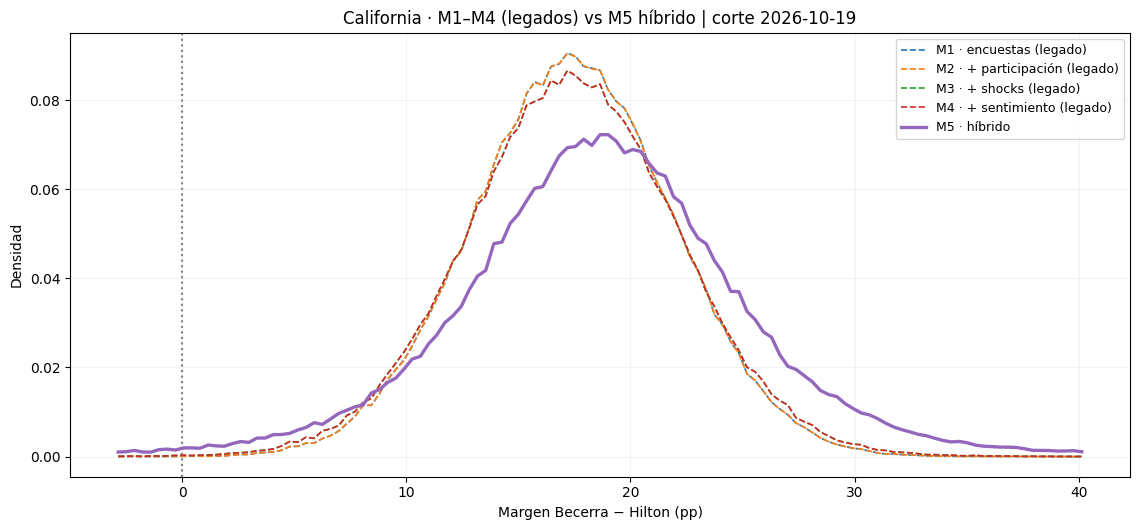

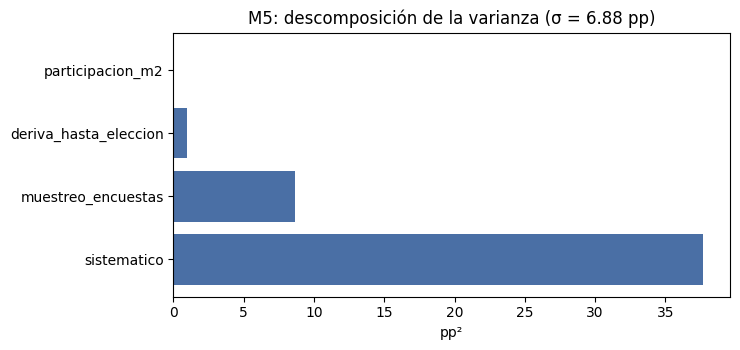

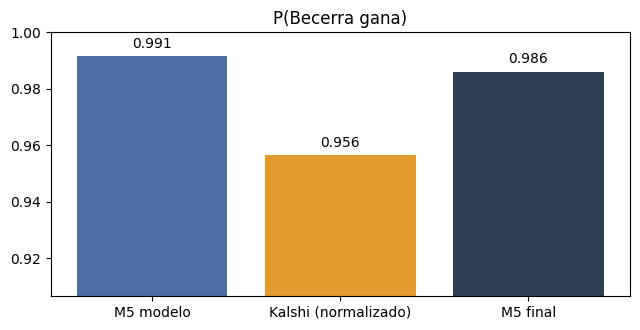

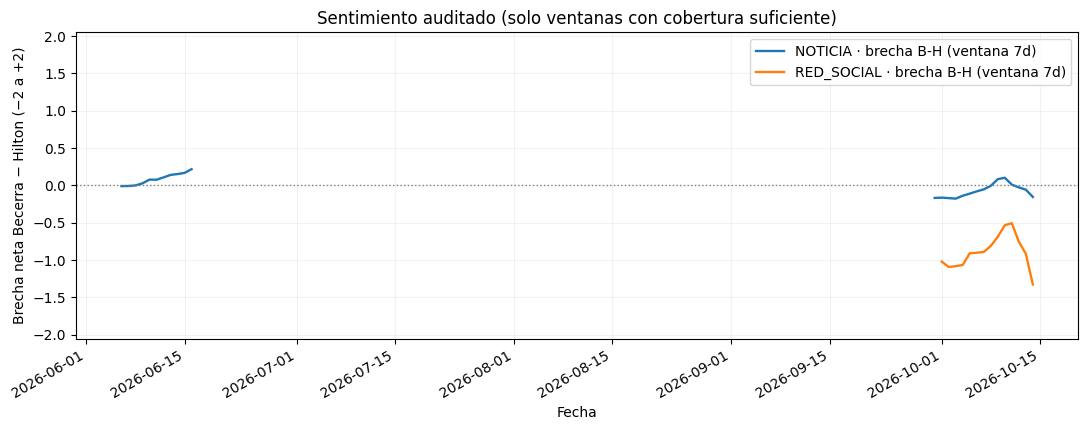

In [14]:
resultado = await actualizar_m5(mostrar_graficas=True)

## 7b. Pronóstico del porcentaje de voto por candidato
El 3 de noviembre solo hay dos candidatos en la boleta (top-two, sin candidatos por escrito), así que %Becerra + %Hilton = 100% del voto válido. Cuando se publique, el resultado oficial también incluye boletas en blanco para este cargo, que no cuentan para estos porcentajes.

### Pronóstico 3-nov · corte 2026-10-19
**Becerra: 59.4%** · **Hilton: 40.6%** (margen +18.7 pp) · P(Becerra gana) modelo 0.991, con Kalshi 0.986

Modelo,Candidato,Pronóstico %,Media %,IC 80% inf,IC 80% sup,IC 95% inf,IC 95% sup,P(ganar)
M5 híbrido,Becerra (D),59.4,59.4,55.4,63.3,52.5,66.2,0.991
M5 híbrido,Hilton (R),40.6,40.6,36.7,44.6,33.8,47.5,0.009
M1 legado (σ 4.5),Becerra (D),58.7,58.7,55.8,61.6,54.3,63.1,1.000
M1 legado (σ 4.5),Hilton (R),41.3,41.3,38.4,44.2,36.9,45.7,0.000


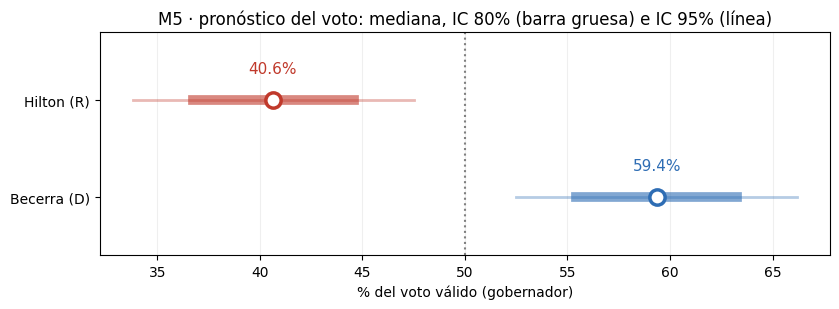

In [15]:
# ---------------------------------------------------------------------------------
# Pronóstico del % de voto de cada candidato (3-nov: solo Becerra y Hilton en la boleta;
# el top-two de California no admite candidatos por escrito, así que %B + %H = 100% de
# los votos válidos para gobernador). Se deriva de la simulación M5: %B = 50 + margen/2.
# Kalshi no entra aquí: el mercado da probabilidad de ganar, no porcentaje de voto.
# ---------------------------------------------------------------------------------
def pronostico_porcentajes(res: dict, incluir_legado: bool = True) -> pd.DataFrame:
    fuentes = {'M5 híbrido': res['m5']['simulacion']}
    if incluir_legado:
        fuentes['M1 legado (σ 4.5)'] = res['sim_legado'].referencia
    filas = []
    for modelo, margen in fuentes.items():
        for cand, signo in ((f'{CANDIDATO_D} (D)', 1), (f'{CANDIDATO_R} (R)', -1)):
            pct = 50 + signo * margen / 2
            q = np.quantile(pct, [.025, .10, .50, .90, .975])
            filas.append({'Modelo': modelo, 'Candidato': cand, 'Pronóstico %': float(np.median(pct)),
                          'Media %': float(pct.mean()), 'IC 80% inf': q[1], 'IC 80% sup': q[3],
                          'IC 95% inf': q[0], 'IC 95% sup': q[4],
                          'P(ganar)': float(np.mean(signo * margen > 0))})
    return pd.DataFrame(filas)


tabla_pct = pronostico_porcentajes(resultado)
tabla_pct.to_csv(SALIDA / 'pronostico_porcentajes.csv', index=False, encoding='utf-8-sig')
m5r = resultado['m5']
display(Markdown(
    f"### Pronóstico 3-nov · corte {resultado['reporte']['fecha_corte']}\n"
    f"**{CANDIDATO_D}: {50 + np.median(m5r['simulacion'])/2:.1f}%** · "
    f"**{CANDIDATO_R}: {50 - np.median(m5r['simulacion'])/2:.1f}%** "
    f"(margen {np.median(m5r['simulacion']):+.1f} pp) · P({CANDIDATO_D} gana) modelo {m5r['p_modelo']:.3f}, "
    f"con Kalshi {m5r['p_final']:.3f}"))
display(tabla_pct.style.format({c: '{:.1f}' for c in tabla_pct.columns if '%' in c or 'IC' in c}
                               | {'P(ganar)': '{:.3f}'}).hide(axis='index'))

m5t = tabla_pct[tabla_pct.Modelo == 'M5 híbrido']
fig, ax = plt.subplots(figsize=(8.5, 3.2))
colores = ['#2e6db4', '#c0392b']
for i, (_, f) in enumerate(m5t.iterrows()):
    ax.plot([f['IC 95% inf'], f['IC 95% sup']], [i, i], color=colores[i], lw=2, alpha=.35)
    ax.plot([f['IC 80% inf'], f['IC 80% sup']], [i, i], color=colores[i], lw=7, alpha=.6)
    ax.plot(f['Pronóstico %'], i, 'o', color='white', mec=colores[i], ms=11, mew=2.5)
    ax.text(f['Pronóstico %'], i + .28, f"{f['Pronóstico %']:.1f}%", ha='center', fontsize=11, color=colores[i])
ax.axvline(50, color='gray', ls=':')
ax.set(yticks=[0, 1], yticklabels=m5t.Candidato, ylim=(-.6, 1.7), xlabel='% del voto válido (gobernador)',
       title='M5 · pronóstico del voto: mediana, IC 80% (barra gruesa) e IC 95% (línea)')
ax.grid(axis='x', alpha=.2)
plt.tight_layout(); plt.savefig(SALIDA / 'pronostico_porcentajes.png', dpi=150); plt.show()


## 8. Pruebas de consistencia

In [16]:
# Pruebas de consistencia (se ejecutan sobre el último resultado)
r = resultado
m5 = r['m5']
assert abs(sum(r['agregado_m5']['pesos']) - 1) < 1e-9
assert abs(m5['sigma_pp'] ** 2 - sum(m5['componentes_varianza_pp2'].values())) < 1e-9
# Con W_M2 = 0 la media de M5 es exactamente el agregado M5
if W_M2 == 0:
    assert abs(m5['media_pp'] - r['agregado_m5']['margen']) < 1e-12
# La t reescalada conserva la varianza objetivo (tolerancia Monte Carlo)
assert abs(np.std(m5['simulacion']) / m5['sigma_pp'] - 1) < 0.03
# Sin Kalshi, p_final = p_modelo
_p = pronostico_m5(r['agregado_m5'], 10, 5.0, p_kalshi=None, n_sim=20_000)
assert _p['p_final'] == _p['p_modelo']
# k_sent se acota a [1, K_SENT_MAX]
assert pronostico_m5(r['agregado_m5'], 10, 5.0, k_sent=9, n_sim=1000)['k_sent_aplicado'] == K_SENT_MAX
# Las internas pesan menos en M5 que en el agregado legado
t = r['tabla_encuestas']
interna = t['Encargada campaña']
assert (t.loc[interna, 'Peso M5'] < t.loc[interna, 'Peso legado']).all()
print('Pruebas M5 OK')


Pruebas M5 OK


## 9. Noche electoral (opcional)

Activa `MODO_CONTEO = True` para apagar Kalshi, que en la primaria sobrerreaccionó al conteo. Con los votos contados y las boletas pendientes (reporte de *unprocessed ballots* del SOS), proyecta el final aplicando el corrimiento tardío medido en la primaria 2026.

In [17]:
# Ejemplo con cifras ilustrativas. Reemplázalas por las del SOS en la noche electoral.
# proyectar_conteo(votos_d=3_000_000, votos_r=2_400_000, boletas_restantes=5_000_000)
print('Corrimiento tardío R medido en la primaria 2026: %+.1f pp' % corrimiento_tardio_primaria())

Corrimiento tardío R medido en la primaria 2026: -12.3 pp
